# GEMS — Phase 2: Geological fault-detection benchmark

**Research questions**

| | question | answered in |
|---|---|---|
| RQ1 | How competitive is terrain-only vs all modalities? | §4 (G1 vs G2), §10 decision 2 |
| RQ2 | Do geology-informed engineered features beat raw bands? | §4 (G3/G4 vs G2), decision 3 |
| RQ3 | Do U-Nets beat feature-based gradient boosting? | §5 vs §4, decision 4 |
| RQ4 | Which models generalise to unseen fault systems? | §2 folds, §7 pseudo-discovery |
| RQ5 | Which models are complementary? | §8 |

**Protocol.** Everything is scored with the *official* distance-weighted Tversky index (DTI, α=0.2, β=0.8, R=300 m) on the **native 100 m grid**, out-of-fold on **geographic folds with buffers**. Pseudo-discovery (withheld fault systems) is a separate stress test, never mixed with the geographic holdout. No number in this notebook is a leaderboard score.

**How to run.** Execute top to bottom. Every expensive step is cached (features in `outputs/benchmark/cache/features/`, runs in `outputs/benchmark/experiments/<exp_id>/`) and skipped when already done; set `OVERWRITE=True` to recompute. Priority switches in the setup cell: run P0 first (`RUN_P1=RUN_CNN=RUN_DISCOVERY=RUN_ENSEMBLE=RUN_SUBMISSION=False`), inspect §4, then enable the rest. `SAMPLE_SCALE=0.2` gives a quick smoke run.

Dependencies: `requirements-bench.txt` (LightGBM, scikit-learn, PyTorch + segmentation-models-pytorch for §5). Reload paths: `outputs/benchmark/manifest.json` and `docs/EXPERIMENT_REGISTRY.md`.

## 0 · Setup

In [6]:
%pip install -U scikit-learn

  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached threadpoolctl-3.7.0-py3-none-any.whl.metadata (24 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
   ---------------------------------------- 0.0/8.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.9 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.9 MB ? eta -:--:--
   - ------------------------------------

In [13]:
%pip install lightgbm

  Using cached lightgbm-4.7.0-py3-none-win_amd64.whl.metadata (18 kB)
  Using cached narwhals-2.27.1-py3-none-any.whl.metadata (15 kB)
Using cached lightgbm-4.7.0-py3-none-win_amd64.whl (1.4 MB)
Using cached narwhals-2.27.1-py3-none-any.whl (483 kB)

   ---------------------------------------- 0/2 [narwhals]
   ---------------------------------------- 0/2 [narwhals]
   ---------------------------------------- 0/2 [narwhals]
   ---------------------------------------- 0/2 [narwhals]
   ---------------------------------------- 0/2 [narwhals]
   ---------------------------------------- 0/2 [narwhals]
   ---------------------------------------- 0/2 [narwhals]
   ---------------------------------------- 0/2 [narwhals]
   ---------------------------------------- 0/2 [narwhals]
   ---------------------------------------- 0/2 [narwhals]
   ---------------------------------------- 0/2 [narwhals]
   ---------------------------------------- 0/2 [narwhals]
   --------------------------------------

In [33]:
%pip install -U tabulate

  Using cached tabulate-0.10.0-py3-none-any.whl.metadata (40 kB)
Using cached tabulate-0.10.0-py3-none-any.whl (39 kB)
Note: you may need to restart the kernel to use updated packages.


In [1]:
import sys, json, time, warnings
from pathlib import Path

ROOT = Path.cwd().resolve()
while not (ROOT / 'gems-geodawn-numerical-features.tif').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from gems_bench.config import BenchConfig, BenchPaths, BenchManifest
from gems_bench.data import load_native
from gems_bench.features import FeatureStore, build_specs, group_features, leakage_audit
from gems_bench.folds import (GeoFolds, DiscoverySplits, make_geo_folds, fold_summary,
                              make_discovery_splits, discovery_summary, ROLE, DROLE)
from gems_bench.metric import dti_components, MaskedScorer
from gems_bench.persist import ExperimentRun, load_registry
from gems_bench.gbm import run_gbm_cv, run_map_baseline, fit_full_gbm, median_best_iteration
from gems_bench.ensemble import read_map, apply_transform_file, pairwise_agreement, build_ensembles
from gems_bench.submission import load_transform
from gems_bench import geo_eval, discovery as disc, report, submission, segments

warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.width', 200, 'display.max_columns', 40)

CFG = BenchConfig()                 # all parameters, persisted in every run's config.json
PATHS = BenchPaths.discover(ROOT)
MAN = BenchManifest(PATHS)
RNG = np.random.default_rng(CFG.seed)

# ---- run switches (priority order) ----
RUN_P1 = True          # engineered features G3/G4, error atlas, pseudo-discovery
RUN_CNN = True         # U-Net baselines (needs torch; GPU strongly recommended)
RUN_DISCOVERY = True
RUN_ENSEMBLE = True
RUN_SUBMISSION = True
SAMPLE_SCALE = 1.0     # 0.2 = quick smoke run of the tabular models
OVERWRITE = False

def save_fig(fig, name, desc='', dpi=130):
    p = PATHS.figures / f'{name}.png'
    fig.savefig(p, dpi=dpi, bbox_inches='tight')
    MAN.add(name, p, 'figure', desc)
    plt.show()
    return p

def save_table(df, name, desc='', where=None):
    p = (where or PATHS.tables) / f'{name}.csv'
    df.to_csv(p, index=False)
    MAN.add(name, p, 'table', desc)
    return p

print('root:', ROOT)
print('outputs:', PATHS.out)

root: C:\Users\myben\Downloads\GEMS
outputs: C:\Users\myben\Downloads\GEMS\outputs\benchmark


## 1 · Reload data on the native 100 m grid and build the feature registry

The EDA ran on a 2× block-averaged 200 m grid (1865 × 1646 px). Phase 2 uses the **native** grid of the feature GeoTIFF for targets, folds, predictions and scoring. Phase-1 rasters are only used as *input features* resampled bilinearly to 100 m (flagged `eda_resampled`), never as labels; `label_context.tif` is never read. Labels follow the organizer convention: value ≥ 1 = mapped fault.

In [2]:
data = load_native(PATHS)
summ = data.summary()
display(summm := summ)
save_table(summ, 'native_grid_summary', 'CRS, shape, pixel size, footprint, label stats on the native grid')
save_table(data.band_table(), 'native_band_table', 'Band names / modality / description (native file)')
assert abs(data.grid.pixel_km - 0.1) < 1e-6, 'expected 100 m pixels'
assert data.template_matches(), 'example_submission.tif grid differs from features grid'
print('label values preview:', data.label_info['values_preview'])

,key,value
0,crs,EPSG:32611
1,height,3730
2,width,3292
3,pixel_m_x,100.0
4,pixel_m_y,100.0
5,n_bands,19
6,valid_frac,0.42070076454741206
7,valid_km2,51658.520000000004
8,label_px,60988
9,label_frac_of_valid,0.011787794152832872


label values preview: [0.0, 1.0]


In [3]:
# Phase-1 artifacts reused here (reload paths from outputs/eda/manifest.json)
eda_man = json.loads((PATHS.eda / 'manifest.json').read_text(encoding='utf-8'))
REUSED = ['windows', 'known_fault_segments', 'known_fault_segments_gpkg', 'segment_archetypes',
          'lineament_maps', 'crossmodal_orientation', 'lineament_candidates', 'fault_morphology_summary',
          'best_transform_per_modality']
reuse = pd.DataFrame([{'name': k, **eda_man.get(k, {'path': 'MISSING'}),
                       'exists': (ROOT / eda_man.get(k, {'path': '_'})['path']).exists()} for k in REUSED])
display(reuse)
EDA_WINDOWS = pd.read_csv(PATHS.eda / 'tables' / 'windows.csv')
morph = json.loads((PATHS.eda / 'tables' / 'fault_morphology_summary.json').read_text())
print('Phase-1 strike families:', morph['strike_families_deg'], '| segments:', morph['n_segments'])

,name,path,kind,description,exists
0,windows,outputs/eda/tables/windows.csv,table,Named zoom windows (pixel and CRS bounds) reus...,True
1,known_fault_segments,outputs/eda/datasets/known_fault_segments.parquet,dataset,Skeleton segments of mapped faults with geometry,True
2,known_fault_segments_gpkg,outputs/eda/datasets/known_fault_segments.gpkg,vector,Mapped fault segments as LineStrings,True
3,segment_archetypes,outputs/eda/datasets/segment_archetypes.parquet,dataset,Segments with evidence + archetype scores/labels,True
4,lineament_maps,outputs/eda/features/lineament_maps.tif,raster,Per-modality ridge responses + fused/support/c...,True
5,crossmodal_orientation,outputs/eda/features/crossmodal_orientation.tif,raster,Structure-tensor strike/coherence per modality...,True
6,lineament_candidates,outputs/eda/datasets/lineament_candidates.parquet,dataset,All detected lineaments with scores and status,True
7,fault_morphology_summary,outputs/eda/tables/fault_morphology_summary.json,table,Headline fault-label morphology numbers,True
8,best_transform_per_modality,outputs/eda/tables/best_transform_per_modality...,table,Best transform/scale per modality,True


Phase-1 strike families: [17.5, 152.5] | segments: 2318


In [4]:
SPECS = build_specs(data.band_names, include_eda=True)
store = FeatureStore(data, SPECS)
for g in ('G1', 'G2', 'G3', 'G4'):
    print(g, len(group_features(SPECS, g)), 'features')

# P0: terrain + raw bands, plus the label-free score maps used by the zero-training floor
P0_FEATURES = sorted(set(group_features(SPECS, 'G1') + group_features(SPECS, 'G2'))) + ['eda:fused_score']
reg = store.build(P0_FEATURES)
MAN.add('feature_registry', store.dir / 'feature_registry.csv', 'table',
        'Feature registry: source band, transform, scale, support, normalisation, cache path')
audit = leakage_audit(list(store.specs.values()), CFG.buffer_km)
save_table(audit, 'leakage_audit', 'Feature input support vs fold buffer (inputs only, never labels)')
display(reg[['name', 'groups', 'modality', 'transform', 'scale_km', 'kind', 'origin', 'support_km', 'cached']].head(60))

G1 19 features
G2 19 features
G3 52 features
G4 72 features
  feature raw:cond_surf                                2.0s  robust-z
  feature raw:depth_to_base_surf                       2.1s  robust-z + signed log
  feature raw:deq_n100a15                              2.1s  robust-z + signed log
  feature raw:det_elev                                 2.0s  robust-z
  feature raw:det_elev_slope                           2.0s  robust-z
  feature raw:geod_2ndinv                              2.0s  robust-z
  feature raw:geod_dilaterate                          2.2s  robust-z
  feature raw:geod_shearrate                           2.2s  robust-z
  feature raw:ieq_n100a15                              2.2s  robust-z
  feature raw:iso_grav_anom                            2.1s  robust-z
  feature raw:iso_grav_anom_hg                         2.1s  robust-z
  feature raw:iso_grav_anom_slope                      2.1s  robust-z
  feature raw:iso_grav_anom_vg                         2.0s  robust-z
  fe

,name,groups,modality,transform,scale_km,kind,origin,support_km,cached
0,raw:mag_anom,"G2,G3,G4",magnetic,raw,0.0,local,native,0.00,True
1,raw:rtp,"G2,G3,G4",magnetic,raw,0.0,local,native,0.00,True
2,raw:tmi_hg,"G2,G3,G4",magnetic,raw,0.0,local,native,0.00,True
3,raw:geod_2ndinv,"G2,G3,G4",strain,raw,0.0,context,native,0.00,True
4,raw:iso_grav_anom_slope,"G2,G3,G4",gravity,raw,0.0,local,native,0.00,True
5,raw:tc,"G2,G3,G4",magnetic,raw,0.0,local,native,0.00,True
6,raw:geod_shearrate,"G2,G3,G4",strain,raw,0.0,context,native,0.00,True
7,raw:geod_dilaterate,"G2,G3,G4",strain,raw,0.0,context,native,0.00,True
8,raw:tmi_vg,"G2,G3,G4",magnetic,raw,0.0,local,native,0.00,True
9,raw:deq_n100a15,"G2,G3,G4",seismicity,raw,0.0,context,native,0.00,True


## 2 · Geographically honest validation

**Geographic holdout** — 20 km blocks → k-means into 3 contiguous clusters per fold → greedy balance of label pixels and area. For fold *k*: `val` is scored; a 13 km `buffer` (≥ half a 256 px patch) is never trained on; one training cluster is the `inner_val` for early stopping / checkpointing, separated by its own 5 km buffer. CNN patches must lie *entirely* inside the training zone. Training-negative selection uses only labels visible to the fold.

**Pseudo-discovery** — whole fault systems (mapped pieces linked within 1 km) are withheld from supervision (weight 0, never negatives) while their input rasters stay visible; ~12 % of trace length per split, region-stratified, 3 disjoint splits. Scored separately in §7.

In [7]:
fold_dir = PATHS.folds / f'geo_k{CFG.n_folds}_b{CFG.block_km:g}km_buf{CFG.buffer_km:g}km_s{CFG.seed}'
if (fold_dir / 'fold_map.tif').exists() and not OVERWRITE:
    folds = GeoFolds.load(fold_dir, data.grid)
else:
    folds = make_geo_folds(data.valid, data.labels, data.grid, n_folds=CFG.n_folds, block_km=CFG.block_km,
                           clusters_per_fold=CFG.clusters_per_fold, buffer_km=CFG.buffer_km, seed=CFG.seed)
    folds.save(fold_dir)
MAN.add('geo_folds', fold_dir / 'fold_map.tif', 'raster', 'fold_id + per-fold role (0 train,1 val,2 buffer,3 inner_val,4 inner_buffer)')
fs = fold_summary(folds, data.labels, data.valid)
fs.to_csv(fold_dir / 'fold_summary.csv', index=False)
MAN.add('geo_fold_summary', fold_dir / 'fold_summary.csv', 'table', 'Pixels, km2, label px, trace km, regions per fold x role')
display(fs.pivot_table(index='fold', columns='role', values='label_px', aggfunc='sum'))
display(fs[fs.role == 'val'][['fold', 'km2', 'label_px', 'trace_km_approx', 'regions']])

role,buffer,inner_buffer,inner_val,train,val
fold,,,,,
0,4719,872,6616,29980,18707
1,2774,353,6133,29626,22008
2,7139,873,7092,25611,20179


,fold,km2,label_px,trace_km_approx,regions
1,0,18878.13,18707,1973.29,"{""NW"": 78400, ""NC"": 561592, ""NE"": 534042, ""SC""..."
6,1,15482.92,22008,2351.36,"{""NW"": 409779, ""NC"": 278244, ""CW"": 438080, ""CC..."
11,2,17297.47,20179,2179.32,"{""NW"": 561034, ""NC"": 306042, ""NE"": 312376, ""CW..."


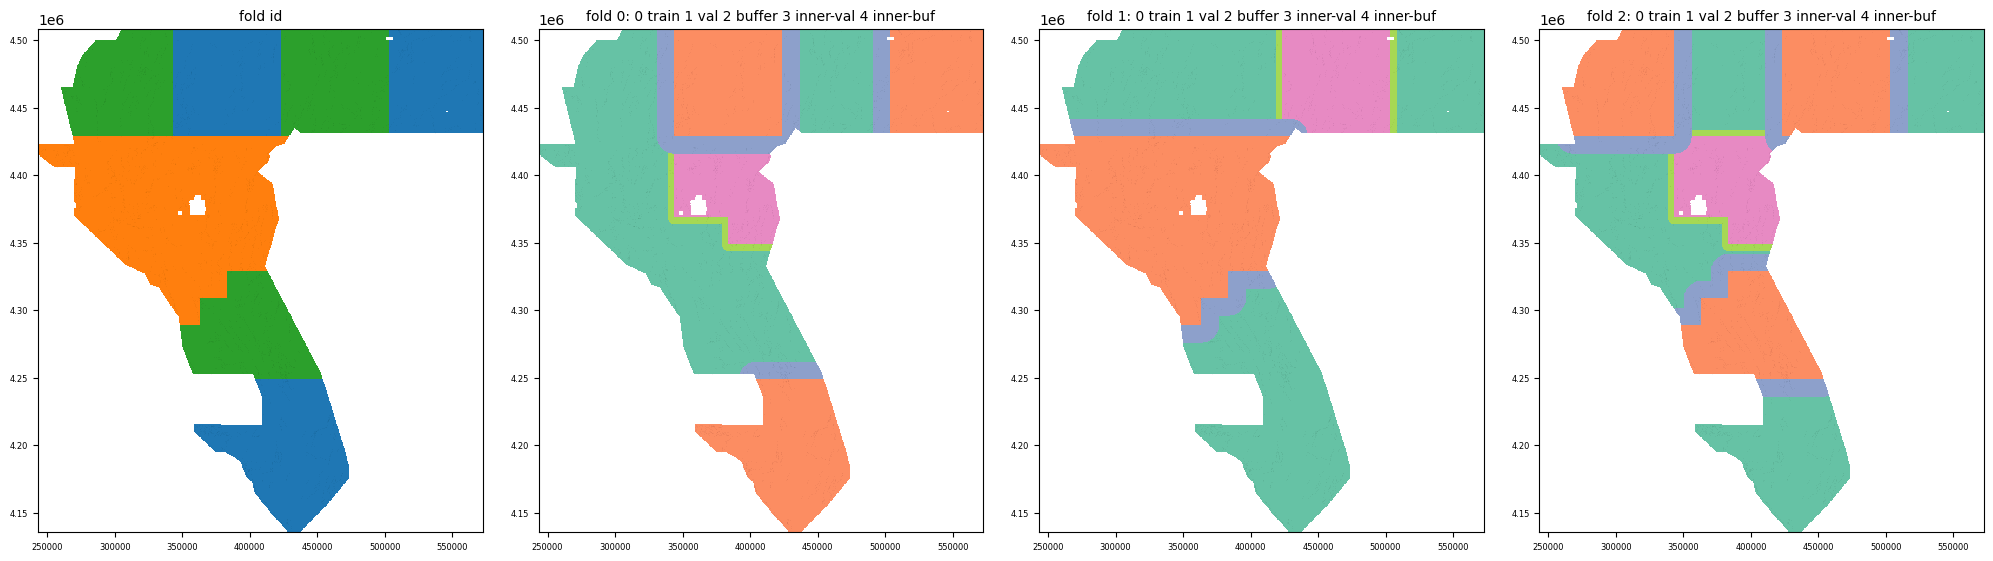

WindowsPath('C:/Users/myben/Downloads/GEMS/outputs/benchmark/figures/folds_geographic.png')

In [8]:
S = 4   # display stride
EXT = data.grid.extent
lr, lc = np.nonzero(data.labels[::S, ::S])
LX, LY = data.grid.rc_to_xy(lr * S, lc * S)

def show(ax, arr, title, **kw):
    ax.imshow(arr[::S, ::S], extent=EXT, interpolation='nearest', **kw)
    ax.set_title(title, fontsize=10)
    ax.set_aspect('equal')
    ax.tick_params(labelsize=6)

def faults(ax, c='k', s=0.05):
    ax.scatter(LX, LY, s=s, c=c, marker='.', linewidths=0)

fig, axs = plt.subplots(1, folds.n_folds + 1, figsize=(5 * (folds.n_folds + 1), 5.5), constrained_layout=True)
show(axs[0], np.where(folds.fold_map >= 0, folds.fold_map, np.nan), 'fold id', cmap='tab10', vmin=0, vmax=9)
faults(axs[0])
for k in range(folds.n_folds):
    show(axs[k + 1], np.where(folds.roles[k] >= 0, folds.roles[k], np.nan),
         f'fold {k}: 0 train 1 val 2 buffer 3 inner-val 4 inner-buf', cmap='Set2', vmin=0, vmax=7)
    faults(axs[k + 1])
save_fig(fig, 'folds_geographic', 'Geographic fold map and per-fold roles')

,split,n_systems,withheld_trace_km,withheld_px,ignore_px,eval_zone_km2,train_positive_px,regions
0,0,38,812.24,7581,159708,17849.27,53407,"{""NC"": 8, ""NW"": 7, ""NE"": 7, ""CC"": 7, ""SC"": 6, ..."
1,1,38,807.84,7472,159348,18493.88,53516,"{""CW"": 9, ""CC"": 7, ""NE"": 6, ""NC"": 6, ""SC"": 6, ..."
2,2,44,783.53,7284,148168,17254.85,53704,"{""CW"": 9, ""NW"": 9, ""SC"": 8, ""NE"": 6, ""NC"": 6, ..."


systems: 599 | total trace km 6513.0


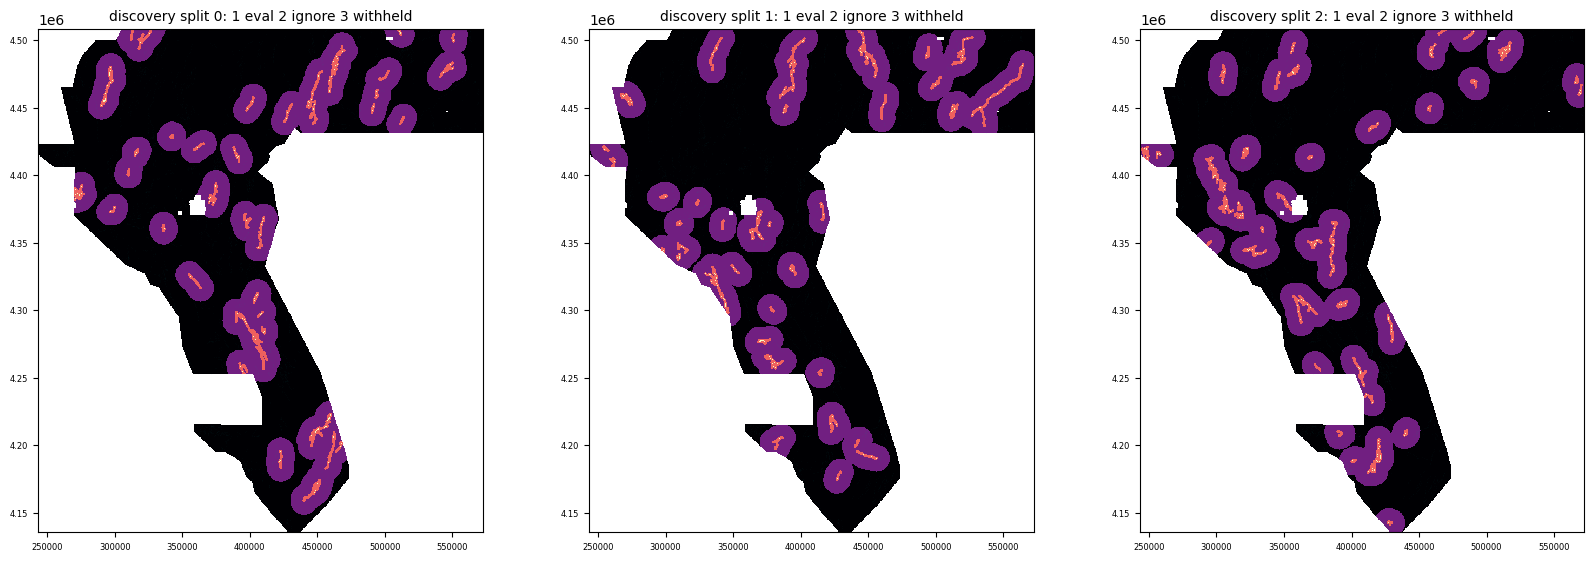

WindowsPath('C:/Users/myben/Downloads/GEMS/outputs/benchmark/figures/folds_discovery.png')

In [9]:
disc_dir = PATHS.folds / f'discovery_d{CFG.n_discovery_folds}_link{CFG.system_link_km:g}km_s{CFG.seed}'
if (disc_dir / 'discovery_map.tif').exists() and not OVERWRITE:
    splits = DiscoverySplits.load(disc_dir, data.grid)
else:
    splits = make_discovery_splits(data.labels, data.valid, data.grid, n_splits=CFG.n_discovery_folds,
                                   link_km=CFG.system_link_km, frac_km=CFG.discovery_frac_km,
                                   min_system_km=CFG.discovery_min_system_km, ignore_km=CFG.discovery_ignore_km,
                                   eval_km=CFG.discovery_eval_km, seed=CFG.seed)
    splits.save(disc_dir)
MAN.add('discovery_splits', disc_dir / 'discovery_map.tif', 'raster', 'system_id + per-split role (1 eval zone, 2 ignore, 3 withheld)')
ds = discovery_summary(splits, data.labels)
ds.to_csv(disc_dir / 'discovery_summary.csv', index=False)
MAN.add('discovery_summary', disc_dir / 'discovery_summary.csv', 'table', 'Withheld systems, km, positives per split')
display(ds.drop(columns='system_ids'))
print('systems:', len(splits.systems), '| total trace km', round(splits.params['total_trace_km'], 1))

fig, axs = plt.subplots(1, splits.n_splits, figsize=(5.5 * splits.n_splits, 5.5), constrained_layout=True)
for d, ax in enumerate(np.atleast_1d(axs)):
    show(ax, np.where(data.valid, splits.roles[d], np.nan), f'discovery split {d}: 1 eval 2 ignore 3 withheld',
         cmap='magma', vmin=0, vmax=3)
    faults(ax, c='c')
save_fig(fig, 'folds_discovery', 'Pseudo-discovery withheld systems per split')

## 3 · The official metric

`gems_bench.metric.dti_components` implements the organizer definition literally: TP_w = Σ_g max_x p(x)k(d), FP_w = Σ_x p(x)[1 − k(dist(x, G))], FN_w = |G| − TP_w, k(d) = max(1 − d/300 m, 0). Choices the organizers leave open are explicit arguments (ε = 1e-6, NaN → 0, evaluation / exclusion masks). The unit tests in `tests/test_metric.py` (perfect, empty, missing segment, 1–2 px shifts, out-of-support, soft, corridor, exclusion, nodata, brute-force formula) are authored for `python -m pytest tests/test_metric.py -q`.

Because DTI depends on the *scale* of probabilities, every run also fits an output transform q = clip(s·p^γ, 0, 1), zeroed below a floor — **cross-fitted** (chosen on the other folds) so the reported number stays out-of-fold. **Pooled DTI** = DTI of the stitched OOF map over the whole footprint (the primary selection metric).

In [10]:
# inline smoke checks (the full suite is tests/test_metric.py)
t = np.zeros((40, 40), bool); t[5:35, 20] = True
assert abs(dti_components(t.astype(float), t).dti - 1) < 1e-4
shift = np.zeros_like(t); shift[5:35, 21] = True
assert abs(dti_components(shift.astype(float), t).dti - 2 / 3) < 1e-4
assert dti_components(np.zeros((40, 40)), t).dti == 0

# reference points on the real grid
zero = dti_components(np.zeros(data.shape, np.float32), data.labels, eval_mask=data.valid)
print('all-zero prediction DTI:', zero.dti, '| n truth px:', zero.n_truth)
for c in (0.01, 0.05):
    print(f'constant p={c}: DTI =', round(dti_components(np.full(data.shape, c, np.float32), data.labels, eval_mask=data.valid).dti, 5))

all-zero prediction DTI: 0.0 | n truth px: 60894
constant p=0.01: DTI = 0.01037
constant p=0.05: DTI = 0.03079


In [11]:
# Zero-training floors (label-free maps; only the cross-fitted output transform is fitted)
RUNS = {}
RUNS['B0_lineament'] = run_map_baseline(f'b0_lineament_fused_s{CFG.seed}', np.asarray(store.get('eda:fused_score')),
                                        data, folds, CFG, 'Phase-1 fused lineament score (200 m -> 100 m)', OVERWRITE)
RUNS['B0_terrain_ridge'] = run_map_baseline(f'b0_terrain_ridge_s{CFG.seed}', np.asarray(store.get('terrain:ridge@1km')),
                                            data, folds, CFG, 'Hessian line response of det_elev at 1 km', OVERWRITE)

[b0_lineament_fused_s2026] pooled DTI raw=0.0607  cross-fitted transform=0.0688  folds 0.0614±0.0065
[b0_terrain_ridge_s2026] pooled DTI raw=0.0606  cross-fitted transform=0.0717  folds 0.0613±0.0078


## 4 · Feature-based benchmarks (LightGBM)

| group | content |
|---|---|
| G1 | terrain only: det_elev, slope, curvature 0.5–5 km, tilt 2/5 km, relief, THDR, ridges, Mexican hat, local std, coherence |
| G2 | all 19 raw channels |
| G3 | G2 + compact engineered set: terrain (G1), magnetic THDR / strike-directional derivatives / log-Gabor / tilt / coherence, gravity THDR / log-Gabor / tilt / directional, basement THDR + tilt, conductivity THDR |
| G4 | G3 + regional context (10–20 km smooths, 10 km THDR / coherence / std, Phase-1 fused lineament layers) |

Sampling (per fold, PU-aware): mapped-fault positives; 0.5–2.5 km near-fault *ring* negatives (hard-but-reliable, localisation); uniform background; 1–2 px ignore band around labels; negatives on top-3 % unsupervised lineament evidence > 2.5 km from labels down-weighted to 0.3. Early stopping on the inner fold only; refit on the full training zone.

In [15]:

import re
from collections import Counter

def sanitize_lgbm_names(names):
    """Generate safe, unique LightGBM feature names."""
    safe = []
    counts = Counter()

    for name in names:
        clean = re.sub(r'[^A-Za-z0-9_]', '_', str(name))
        clean = re.sub(r'_+', '_', clean).strip('_')

        if not clean:
            clean = "feature"

        counts[clean] += 1
        if counts[clean] > 1:
            clean = f"{clean}_{counts[clean]}"

        # Guard against collisions with names already emitted
        base = clean
        suffix = 2
        while clean in safe:
            clean = f"{base}_{suffix}"
            suffix += 1

        safe.append(clean)

    return safe


# Patch the imported function used by run_gbm_cv.
# Keep original names for store.sample() and use safe names only
# when constructing the LightGBM Dataset.
import gems_bench.gbm as gbm

_original_train_lgbm = gbm.train_lgbm

def train_lgbm_safe(X, y, w, Xv, yv, wv, params,
                    rounds, early_stop, names):
    safe_names = sanitize_lgbm_names(names)

    return _original_train_lgbm(
        X, y, w, Xv, yv, wv,
        params, rounds, early_stop, safe_names
    )

gbm.train_lgbm = train_lgbm_safe

print("LightGBM feature-name sanitization enabled.")

for group in ("G1", "G2"):
    names = group_features(SPECS, group, store.available)
    unsafe = [(a, b) for a, b in zip(names, sanitize_lgbm_names(names))
              if str(a) != b]

    print(f"\n{group}: {len(names)} features, "
          f"{len(unsafe)} sanitized")
    print("Examples:", unsafe[:10])


LightGBM feature-name sanitization enabled.

G1: 19 features, 19 sanitized
Examples: [('raw:det_elev', 'raw_det_elev'), ('raw:det_elev_slope', 'raw_det_elev_slope'), ('terrain:curvature@0.5km', 'terrain_curvature_0_5km'), ('terrain:curvature@1km', 'terrain_curvature_1km'), ('terrain:curvature@2km', 'terrain_curvature_2km'), ('terrain:curvature@5km', 'terrain_curvature_5km'), ('terrain:tilt_edge@2km', 'terrain_tilt_edge_2km'), ('terrain:relief@2km', 'terrain_relief_2km'), ('terrain:tilt_edge@5km', 'terrain_tilt_edge_5km'), ('terrain:relief@5km', 'terrain_relief_5km')]

G2: 19 features, 19 sanitized
Examples: [('raw:mag_anom', 'raw_mag_anom'), ('raw:rtp', 'raw_rtp'), ('raw:tmi_hg', 'raw_tmi_hg'), ('raw:geod_2ndinv', 'raw_geod_2ndinv'), ('raw:iso_grav_anom_slope', 'raw_iso_grav_anom_slope'), ('raw:tc', 'raw_tc'), ('raw:geod_shearrate', 'raw_geod_shearrate'), ('raw:geod_dilaterate', 'raw_geod_dilaterate'), ('raw:tmi_vg', 'raw_tmi_vg'), ('raw:deq_n100a15', 'raw_deq_n100a15')]


In [16]:

for g in ("G1", "G2"):
    names = group_features(SPECS, g, store.available)

    RUNS[f"lgbm_{g}"] = run_gbm_cv(
        f"lgbm_{g}_s{CFG.seed}",
        g,
        names,
        data,
        store,
        folds,
        CFG,
        sample_scale=SAMPLE_SCALE,
        overwrite=OVERWRITE,
    )


[lgbm_G1_s2026] fold 0: DTI=0.0502  AUC=0.709  it=7
[lgbm_G1_s2026] fold 1: DTI=0.0672  AUC=0.639  it=3
[lgbm_G1_s2026] fold 2: DTI=0.0592  AUC=0.663  it=11
[lgbm_G1_s2026] pooled DTI raw=0.0584  cross-fitted transform=0.0644  folds 0.0589±0.0070
[lgbm_G2_s2026] fold 0: DTI=0.0528  AUC=0.662  it=24
[lgbm_G2_s2026] fold 1: DTI=0.0679  AUC=0.611  it=7
[lgbm_G2_s2026] fold 2: DTI=0.0551  AUC=0.552  it=2
[lgbm_G2_s2026] pooled DTI raw=0.0585  cross-fitted transform=0.0671  folds 0.0586±0.0067


In [17]:
# Minimal P0 comparison (re-run after each section; §10 writes the final version)
def current_summary():
    s = report.benchmark_summary(PATHS, RUNS)
    cols = ['model', 'status', 'dti_pooled_raw', 'dti_pooled_crossfit_tf', 'dti_fold_mean', 'dti_fold_std',
            'dti_fold_min', 'roc_auc', 'recall@100m', 'precision@100m', 'train_seconds']
    return s[[c for c in cols if c in s]]
display(current_summary().round(4))
for k in ('lgbm_G1', 'lgbm_G2'):
    if RUNS[k].done:
        display(Markdown(f'**{k}** per fold')); display(report.fold_table(RUNS[k])[['fold', 'dti', 'tp_w', 'fp_w', 'fn_w', 'roc_auc']].round(4))

,model,status,dti_pooled_raw,dti_pooled_crossfit_tf,dti_fold_mean,dti_fold_std,dti_fold_min,roc_auc,recall@100m,precision@100m,train_seconds
0,B0_lineament,done,0.0607,0.0688,0.0614,0.0065,0.0547,0.5571,0.5918,0.0404,0.00
1,B0_terrain_ridge,done,0.0606,0.0717,0.0613,0.0078,0.0513,0.5553,0.6665,0.0405,0.00
2,lgbm_G1,done,0.0584,0.0644,0.0589,0.0070,0.0502,0.6636,0.6615,0.0548,19.02
3,lgbm_G2,done,0.0585,0.0671,0.0586,0.0067,0.0528,0.6255,0.5202,0.0517,16.25


**lgbm_G1** per fold

,fold,dti,tp_w,fp_w,fn_w,roc_auc
0,0,0.0502,9569.5105,869516.1066,9137.4895,0.7086
1,1,0.0672,11015.2324,720540.1992,10992.7676,0.6388
2,2,0.0592,10185.7576,768906.0443,9993.2424,0.6634


**lgbm_G2** per fold

,fold,dti,tp_w,fp_w,fn_w,roc_auc
0,0,0.0528,8873.0508,756679.7253,9833.9492,0.6616
1,1,0.0679,11055.2952,714430.9517,10952.7048,0.6105
2,2,0.0551,9854.3672,803079.7548,10324.6328,0.5520


In [18]:
# P1: engineered (G3) and context (G4) features
if RUN_P1:
    store.build(group_features(SPECS, 'G4'))          # G4 is a superset of G3
    for g in ('G3', 'G4'):
        names = group_features(SPECS, g, store.available)
        RUNS[f'lgbm_{g}'] = run_gbm_cv(f'lgbm_{g}_s{CFG.seed}', g, names, data, store, folds, CFG,
                                       sample_scale=SAMPLE_SCALE, overwrite=OVERWRITE)
    display(current_summary().round(4))

  feature magnetic:thdr@1km                            3.8s  robust-z + signed log
  feature magnetic:thdr@2km                            2.6s  robust-z + signed log
  feature magnetic:dirderiv_s17.5@2km                  2.8s  robust-z + signed log
  feature gravity:dirderiv_s17.5@2km                   4.2s  robust-z
  feature magnetic:dirderiv_s152.5@2km                 2.5s  robust-z + signed log
  feature gravity:dirderiv_s152.5@2km                  2.4s  robust-z
  feature magnetic:log_gabor@2km                      19.2s  robust-z + signed log
  feature magnetic:log_gabor@5km                      18.4s  robust-z + signed log
  feature magnetic:tilt@2km                            7.4s  robust-z
  feature magnetic:coherence@2km                       9.3s  robust-z
  feature gravity:thdr@2km                             2.4s  robust-z
  feature gravity:log_gabor@2km                       19.9s  robust-z
  feature gravity:tilt@2km                             8.1s  robust-z
  feature ba

,model,status,dti_pooled_raw,dti_pooled_crossfit_tf,dti_fold_mean,dti_fold_std,dti_fold_min,roc_auc,recall@100m,precision@100m,train_seconds
0,B0_lineament,done,0.0607,0.0688,0.0614,0.0065,0.0547,0.5571,0.5918,0.0404,0.00
1,B0_terrain_ridge,done,0.0606,0.0717,0.0613,0.0078,0.0513,0.5553,0.6665,0.0405,0.00
2,lgbm_G1,done,0.0584,0.0644,0.0589,0.0070,0.0502,0.6636,0.6615,0.0548,19.02
3,lgbm_G2,done,0.0585,0.0671,0.0586,0.0067,0.0528,0.6255,0.5202,0.0517,16.25
4,lgbm_G3,done,0.0612,0.0815,0.0617,0.0087,0.0536,0.6621,0.5216,0.0613,27.38
5,lgbm_G4,done,0.0597,0.0769,0.0602,0.0080,0.0514,0.6526,0.5007,0.0607,30.97


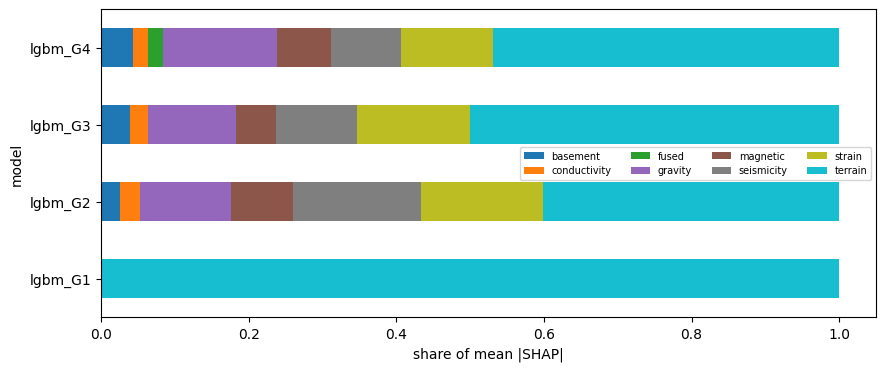

,feature,shap,gain,modality,model
4,raw:det_elev_slope,0.133755,0.145724,terrain,lgbm_G2
20,raw:det_elev_slope,0.094971,0.058155,terrain,lgbm_G3
48,terrain:thdr@0.5km,0.092557,0.053264,terrain,lgbm_G3
19,raw:det_elev,0.079641,0.079972,terrain,lgbm_G3
3,raw:det_elev,0.076587,0.132663,terrain,lgbm_G2
36,raw:det_elev_slope,0.076432,0.052268,terrain,lgbm_G4
18,raw:deq_n100a15,0.068404,0.073563,seismicity,lgbm_G3
21,raw:geod_2ndinv,0.067301,0.082408,strain,lgbm_G3
0,raw:det_elev,0.067030,0.231561,terrain,lgbm_G1
67,terrain:thdr@0.5km,0.063448,0.047330,terrain,lgbm_G4


In [19]:
# Importance by modality (gain and bounded-sample SHAP) for every finished GBM
mod_of = {s.name: s.modality for s in SPECS}
rows = []
for k, r in RUNS.items():
    if r.family != 'gbm' or not r.done or 'shap_summary' not in r.state['artifacts']:
        continue
    sh = r.table('shap_summary').groupby('feature').mean_abs_shap.mean()
    im = r.table('importance').groupby('feature').gain.mean()
    df = pd.DataFrame({'shap': sh, 'gain': im / im.sum()}).reset_index().rename(columns={'index': 'feature'})
    df['modality'] = df.feature.map(mod_of)
    df['model'] = k
    rows.append(df)
if rows:
    imp = pd.concat(rows)
    save_table(imp, 'gbm_importance_all', 'Gain share and mean |SHAP| per feature and model')
    bym = imp.groupby(['model', 'modality']).shap.sum().unstack(fill_value=0)
    fig, ax = plt.subplots(figsize=(10, 4))
    (bym.T / bym.sum(1)).T.plot.barh(stacked=True, ax=ax, colormap='tab10')
    ax.set_xlabel('share of mean |SHAP|'); ax.legend(fontsize=7, ncol=4)
    save_fig(fig, 'gbm_shap_by_modality', 'SHAP share per modality for each GBM')
    display(imp.sort_values('shap', ascending=False).groupby('model').head(10))

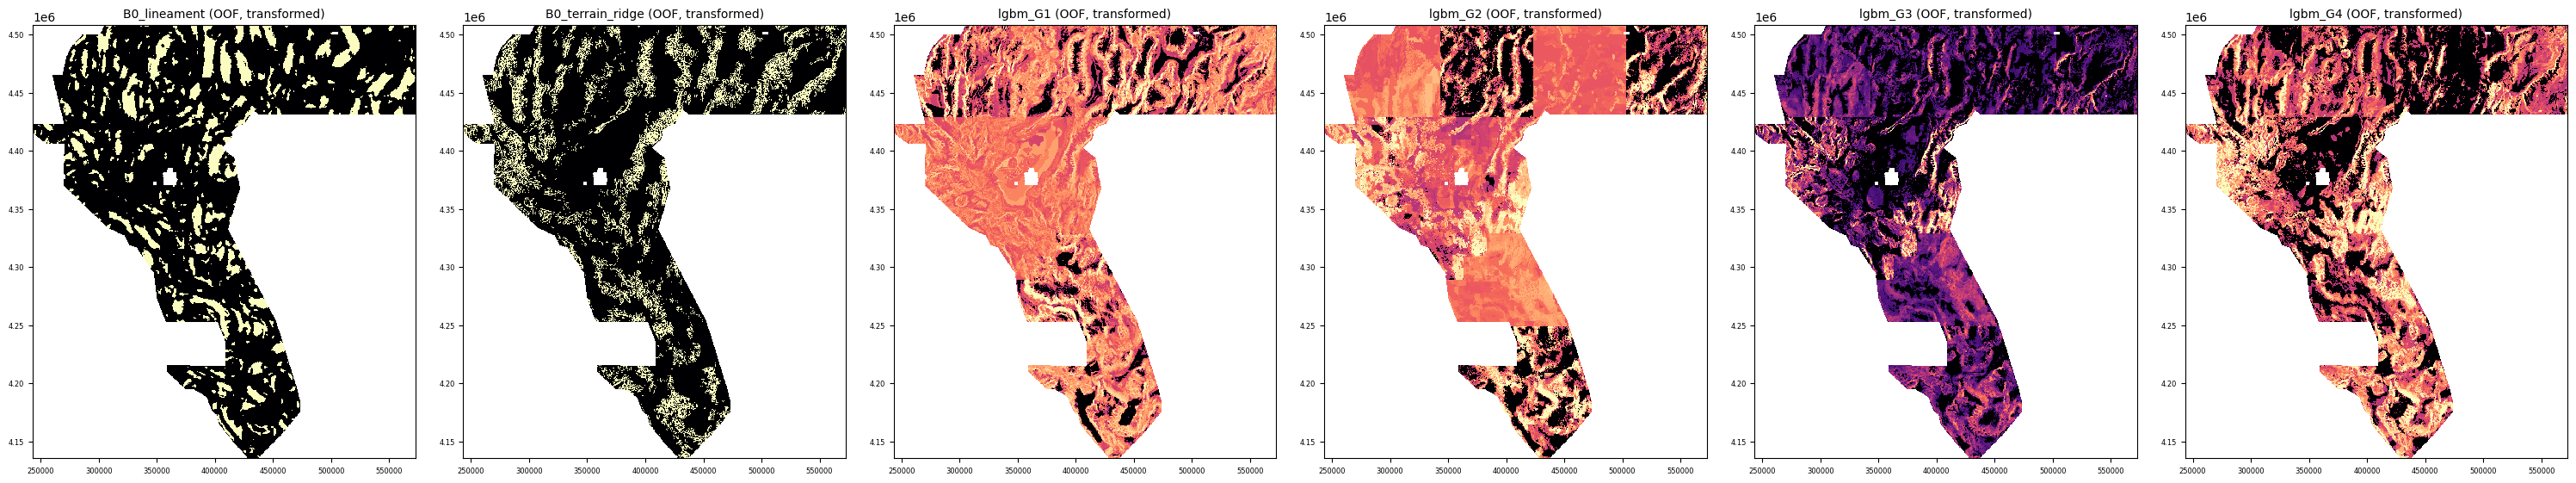

WindowsPath('C:/Users/myben/Downloads/GEMS/outputs/benchmark/figures/oof_maps_overview.png')

In [20]:
# Representative full-region OOF maps (after each run's cross-fitted output transform)
def oof_tf(run):
    return apply_transform_file(read_map(run.oof_path), load_transform(run.dir))

done = [k for k, r in RUNS.items() if r.done]
fig, axs = plt.subplots(1, len(done), figsize=(5 * len(done), 5.5), constrained_layout=True)
for ax, k in zip(np.atleast_1d(axs), done):
    show(ax, oof_tf(RUNS[k]), f'{k} (OOF, transformed)', cmap='magma', vmin=0, vmax=1)
save_fig(fig, 'oof_maps_overview', 'Stitched OOF probability maps per model')

## 5 · Supervised segmentation baseline (U-Net)

Organizer reference (`drivendataorg/gems-prize-reference-solution`): smp U-Net, min-max inputs, Tversky loss, random CV splits, averaged iterations. Its encoder / epochs / α, β were not visible in the published notebook; `reference_spec()` marks them as unverified. Here the same family is trained on the **geographic** folds.

* **CNN-A** raw 19 bands — BCE + Dice, and Tversky (α=0.2, β=0.8: mirrors the metric's FN emphasis).
* **CNN-B** raw + selected EDA-supported enhancements.

Patches 256 px (25.6 km ≥ EDA 9 km response width × 2), 70 % fault-centred; fully inside the training zone; Hann-blended tiled inference at 50 % overlap; checkpoint = best inner-val DTI.

In [21]:
from gems_bench.cnn import CNNSpec, reference_spec, run_cnn_cv

RAW = group_features(SPECS, 'G2')
ENH = ['terrain:curvature@1km', 'terrain:tilt_edge@5km', 'terrain:ridge@1km', 'terrain:relief@2km',
       'magnetic:thdr@2km', 'magnetic:log_gabor@5km', 'magnetic:coherence@2km', 'gravity:thdr@2km',
       'gravity:log_gabor@2km', 'basement:tilt_edge@10km']
common = dict(patch_px=CFG.patch_px, epochs=CFG.epochs, steps_per_epoch=CFG.steps_per_epoch,
              batch_size=CFG.batch_size, lr=CFG.lr, pos_patch_frac=CFG.pos_patch_frac, amp=CFG.amp, seed=CFG.seed)
CNN_SPECS = {
    'cnn_A_bcedice': (CNNSpec('cnn_A_bcedice', RAW, loss='bce_dice', **common), 'CNN-A raw'),
    'cnn_A_tversky': (CNNSpec('cnn_A_tversky', RAW, loss='tversky', **common), 'CNN-A raw'),
    'cnn_B_bcedice': (CNNSpec('cnn_B_bcedice', RAW + ENH, loss='bce_dice', **common), 'CNN-B raw+enh'),
}
if RUN_CNN:
    try:
        import torch
        print('torch', torch.__version__, '| cuda', torch.cuda.is_available())
    except ImportError:
        RUN_CNN = False
        print('torch not installed -> skipping section 5')
if RUN_CNN:
    store.build(sorted(set(RAW + ENH)))
    for k, (spec, inp) in CNN_SPECS.items():
        RUNS[k] = run_cnn_cv(f'{k}_p{spec.patch_px}_s{CFG.seed}', spec, data, store, folds, CFG,
                             input_config=inp, overwrite=OVERWRITE)
    display(current_summary().round(4))

torch not installed -> skipping section 5


In [22]:
# Training curves (loss and inner-validation DTI) per CNN and fold
cnn_done = [k for k, r in RUNS.items() if r.family == 'cnn' and r.done]
if cnn_done:
    fig, axs = plt.subplots(2, len(cnn_done), figsize=(5 * len(cnn_done), 7), squeeze=False, constrained_layout=True)
    for j, k in enumerate(cnn_done):
        h = RUNS[k].table('history')
        for f, g in h.groupby('fold'):
            axs[0, j].plot(g.epoch, g.train_loss, label=f'fold {f}')
            if 'inner_val_dti' in g:
                axs[1, j].plot(g.epoch, g.inner_val_dti, label=f'fold {f}')
        axs[0, j].set_title(f'{k}: train loss'); axs[1, j].set_title('inner-val DTI'); axs[0, j].legend(fontsize=7)
    save_fig(fig, 'cnn_training_curves', 'CNN loss and inner-validation DTI per fold')

## 6 · Geological error analysis

Phase-1 segments (200 m traces) are burned onto the native grid and every native label pixel takes the nearest segment ID within 300 m, so all Phase-1 attributes (length, strike, sinuosity, curvature, junctions, archetype, region) are reused. A segment's **weighted recall** is the mean metric TP support M(g) along its native pixels; *recovered* = weighted recall ≥ 0.5.

In [23]:
seg_path = PATHS.out / 'datasets' / 'native_segment_ids.tif'
seg_path.parent.mkdir(exist_ok=True)
if seg_path.exists() and not OVERWRITE:
    SEG = segments.load_segment_raster(seg_path)
else:
    SEG = segments.segment_id_raster(data)
    segments.save_segment_raster(data, SEG, seg_path)
MAN.add('native_segment_ids', seg_path, 'raster', 'Phase-1 seg_id per native label pixel (-1 = unassigned)')
SEG_TAB = segments.load_segment_table(PATHS.eda)
SEG_TAB.to_parquet(PATHS.out / 'datasets' / 'segment_attributes.parquet', index=False)
MAN.add('segment_attributes', PATHS.out / 'datasets' / 'segment_attributes.parquet', 'dataset', 'Phase-1 segment attributes + strata bins')
print('label px assigned to a Phase-1 segment:', round(float((SEG >= 0).sum() / data.labels.sum()), 3))
print(SEG_TAB.primary_archetype.value_counts().to_dict())

label px assigned to a Phase-1 segment: 0.921
{'unassigned': 1997, 'multi_modal': 190, 'moderate_mixed': 75, 'gravity_related': 37, 'terrain_visible': 15, 'strong_magnetic': 4}


In [24]:
summary_now = report.benchmark_summary(PATHS, RUNS)
ok = summary_now[summary_now.status == 'done']
def best_of(family):
    s = ok[ok.family == family].sort_values('dti_pooled_crossfit_tf')
    return s.model.iloc[-1] if len(s) else None
BEST_GBM, BEST_CNN = best_of('gbm'), best_of('cnn')
ANALYSE = [m for m in dict.fromkeys(['lgbm_G1', BEST_GBM, BEST_CNN, 'B0_lineament']) if m and m in RUNS and RUNS[m].done]
print('best GBM:', BEST_GBM, '| best CNN:', BEST_CNN, '| analysed:', ANALYSE)

MAPS = {m: oof_tf(RUNS[m]) for m in ANALYSE}
REC, STRAT = {}, []
for m, p in MAPS.items():
    REC[m] = geo_eval.segment_recovery(p, data, SEG, SEG_TAB, folds.fold_map, threshold=CFG.report_threshold)
    REC[m].to_parquet(PATHS.out / 'datasets' / f'segment_recovery_{m}.parquet', index=False)
    s = geo_eval.stratified_recall(REC[m]); s.insert(0, 'model', m); STRAT.append(s)
STRAT = pd.concat(STRAT, ignore_index=True)
save_table(STRAT, 'fault_recovery_by_archetype', 'Weighted recall by length/strike/sinuosity/curvature/junction/archetype/region/fold', PATHS.out)
display(STRAT[STRAT.stratum == 'primary_archetype'].pivot_table(index='value', columns='model', values='weighted_recall').round(3))
display(STRAT[STRAT.stratum == 'length_bin'].pivot_table(index='value', columns='model', values='weighted_recall').round(3))

best GBM: lgbm_G3 | best CNN: None | analysed: ['lgbm_G1', 'lgbm_G3', 'B0_lineament']


model,B0_lineament,lgbm_G1,lgbm_G3
value,,,
gravity_related,0.086,0.756,0.366
moderate_mixed,0.196,0.779,0.391
multi_modal,0.410,0.798,0.463
strong_magnetic,0.000,0.762,0.368
terrain_visible,0.334,0.636,0.288
unassigned,0.266,0.733,0.346


model,B0_lineament,lgbm_G1,lgbm_G3
value,,,
1-2,0.254,0.726,0.338
2-5,0.268,0.738,0.351
5-10,0.302,0.781,0.402
<1,0.284,0.716,0.334
>10,0.394,0.827,0.539


In [25]:
# Which faults are recovered by all / one / no model?  Regional and per-fold DTI.
if len(REC) >= 2:
    WIDE, OVER = geo_eval.recovery_overlap(REC)
    WIDE.to_parquet(PATHS.out / 'datasets' / 'segment_recovery_overlap.parquet', index=False)
    save_table(OVER, 'segment_recovery_overlap', 'Recovered trace km: both / only-a / only-b / neither')
    display(OVER.round(1))
    missed = WIDE[WIDE.n_models_recovering == 0].merge(SEG_TAB[['seg_id', 'strike_sector', 'sinuosity_bin', 'region']], on='seg_id', how='left')
    display(Markdown('**Consistently missed segments by archetype / strike (km)**'))
    display(missed.groupby(['primary_archetype']).length_km.sum().sort_values(ascending=False).round(1).to_frame().T)
REG = geo_eval.region_map(data)
reg_rows = []
for m, p in MAPS.items():
    r = geo_eval.dti_by_region(p, data, REG); r.insert(0, 'model', m); reg_rows.append(r)
REG_DTI = pd.concat(reg_rows)
save_table(REG_DTI, 'dti_by_region', 'DTI per Phase-1 3x3 region and model (OOF, transformed)')
display(REG_DTI.pivot_table(index='region_name', columns='model', values='dti').round(4))

,model_a,model_b,both_km,only_a_km,only_b_km,neither_km,jaccard_segments
0,lgbm_G1,lgbm_G3,1616.9,3629.1,8.9,285.7,0.3
1,lgbm_G1,B0_lineament,1494.0,3752.1,67.3,227.3,0.3
2,lgbm_G3,B0_lineament,630.8,995.0,930.4,2984.3,0.2
3,lgbm_G1,(unique vs all),NaN,2758.5,NaN,NaN,NaN
4,lgbm_G3,(unique vs all),NaN,1.4,NaN,NaN,NaN
5,B0_lineament,(unique vs all),NaN,59.8,NaN,NaN,NaN
6,(none),(missed by all),NaN,NaN,NaN,225.9,NaN


**Consistently missed segments by archetype / strike (km)**

primary_archetype,unassigned,multi_modal,terrain_visible,moderate_mixed,gravity_related
length_km,144.4,41.5,25.0,10.3,4.6


model,B0_lineament,lgbm_G1,lgbm_G3
region_name,,,
CC,0.0651,0.0775,0.0855
CW,0.0588,0.0628,0.0754
NC,0.0712,0.0563,0.0796
NE,0.0663,0.0495,0.0744
NW,0.0670,0.0681,0.0751
SC,0.0804,0.0839,0.0903
SE,0.0121,0.0476,0.0489


,cand_id,length_km,area_px,p_mean,p_max,r,c,x,y,dist_to_mapped_km,nearest_eda_candidate_km,eda_candidate_idx,score
0,5794,745.47,28683.0,0.620,0.944,3306.063,1920.505,435450.535,4177893.742,1.005,10.205,68,461.880
1,2590,606.43,25249.0,0.716,1.000,1320.070,380.820,281482.007,4376493.014,1.005,7.346,43,434.371
2,3708,389.40,18221.0,0.796,1.000,1898.475,1327.009,376100.851,4318652.494,1.005,15.252,53,309.895
3,4612,387.42,10095.0,0.551,0.711,2295.267,1806.716,424071.590,4278973.294,1.005,14.410,103,213.443
4,3844,334.73,10146.0,0.576,0.700,1941.452,1658.676,409267.613,4314354.810,1.005,4.714,52,192.744
5,1002,247.50,12731.0,0.624,1.000,710.932,519.737,295373.718,4437406.763,1.005,10.119,32,154.329
6,3341,172.81,7424.0,0.812,1.000,1665.566,1260.108,369410.816,4341943.359,1.005,12.678,45,140.239
7,4235,176.00,8785.0,0.740,1.000,2104.703,1135.582,356958.179,4298029.744,1.005,14.243,55,130.265
8,3336,136.95,7421.0,0.851,1.000,1664.332,1634.675,406867.525,4342066.770,1.005,3.319,100,116.496
9,3030,135.30,5650.0,0.760,1.000,1480.978,1691.451,412545.133,4360402.248,1.005,19.052,100,102.814


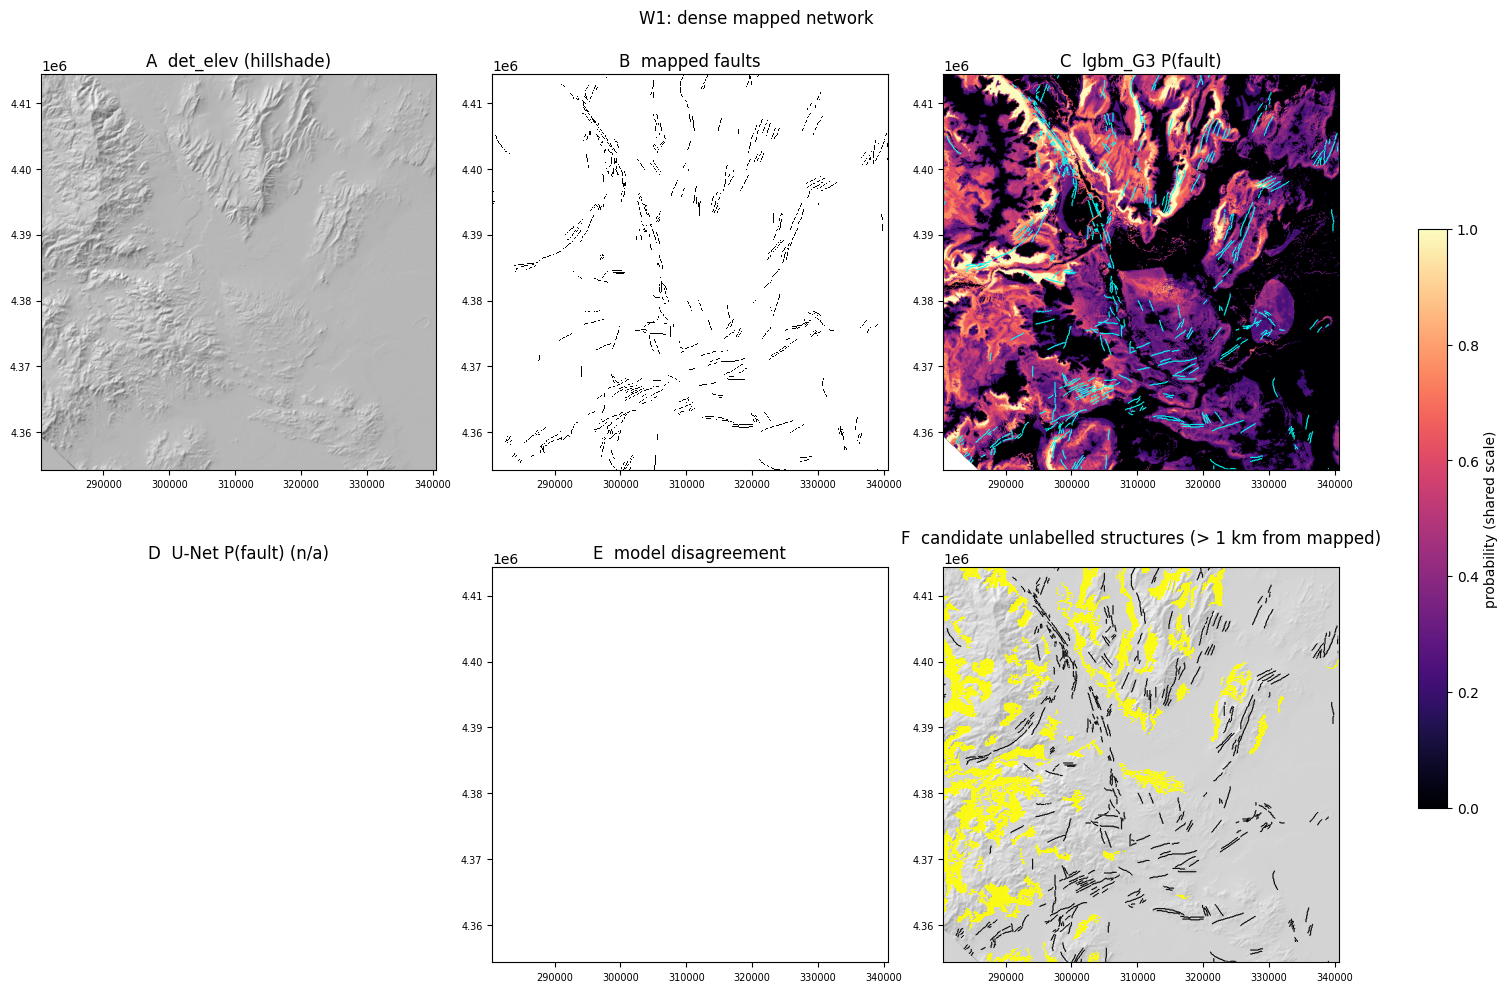

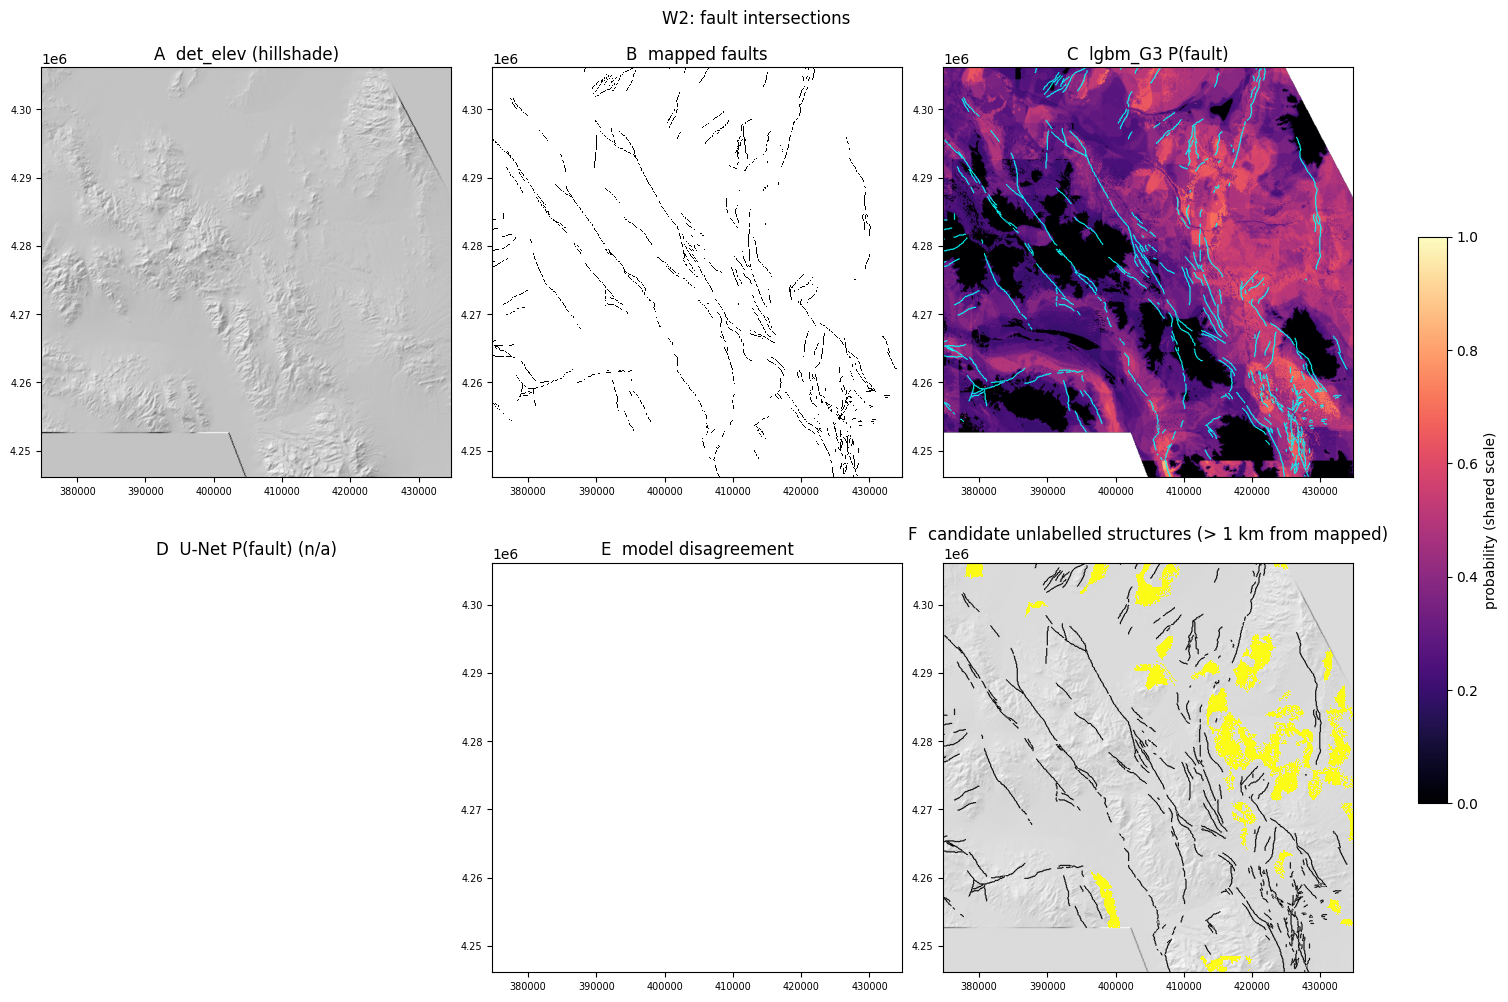

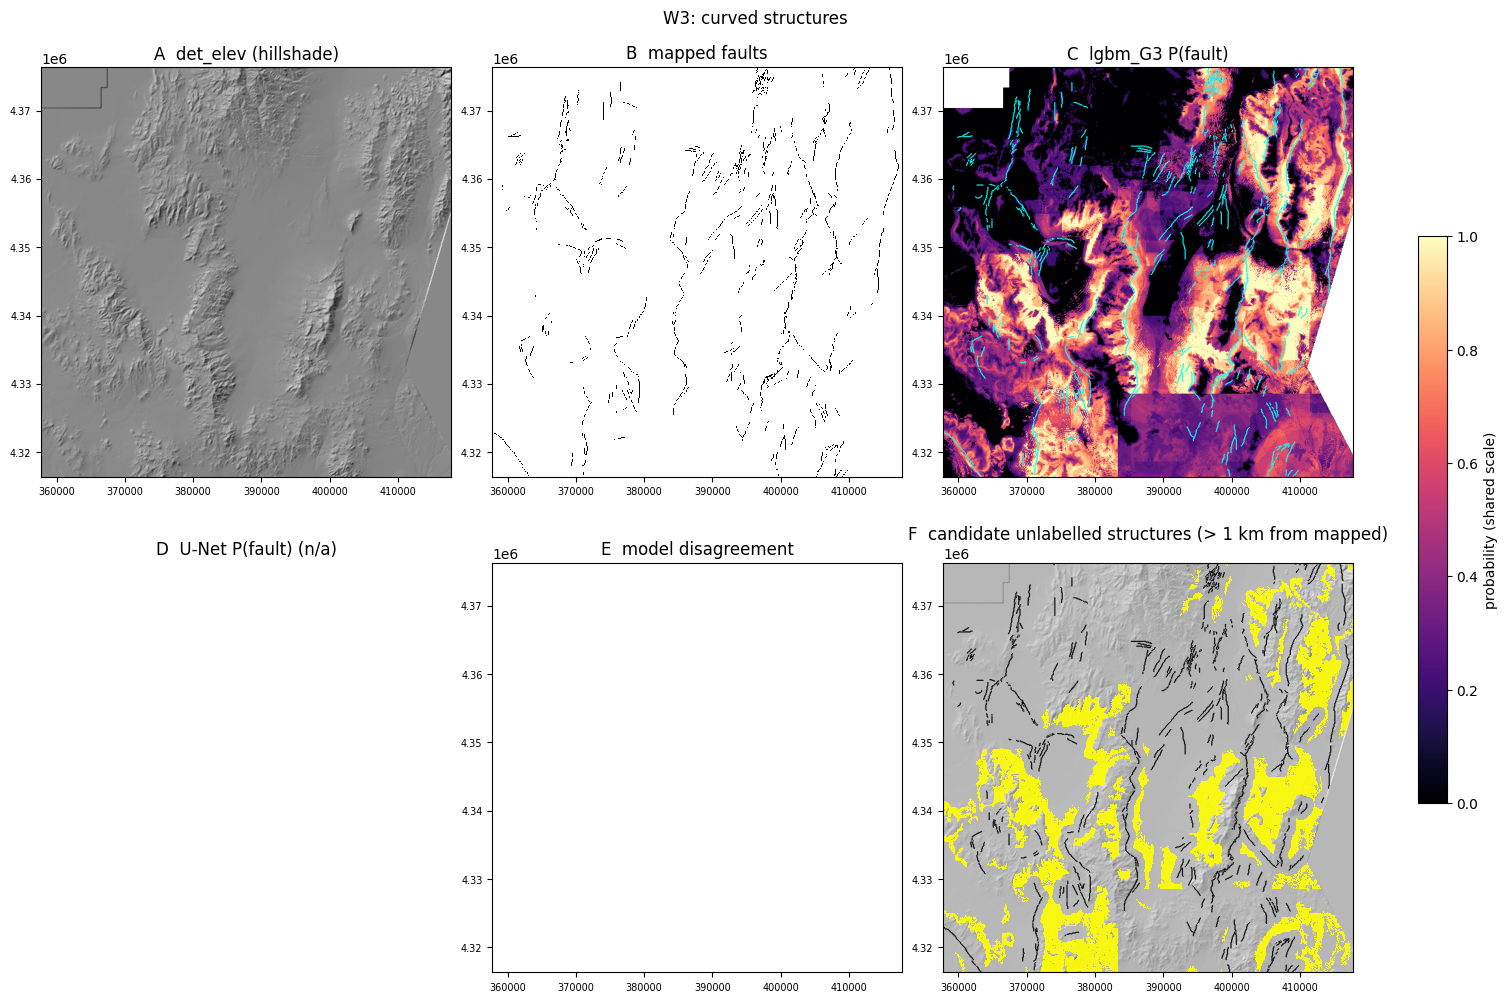

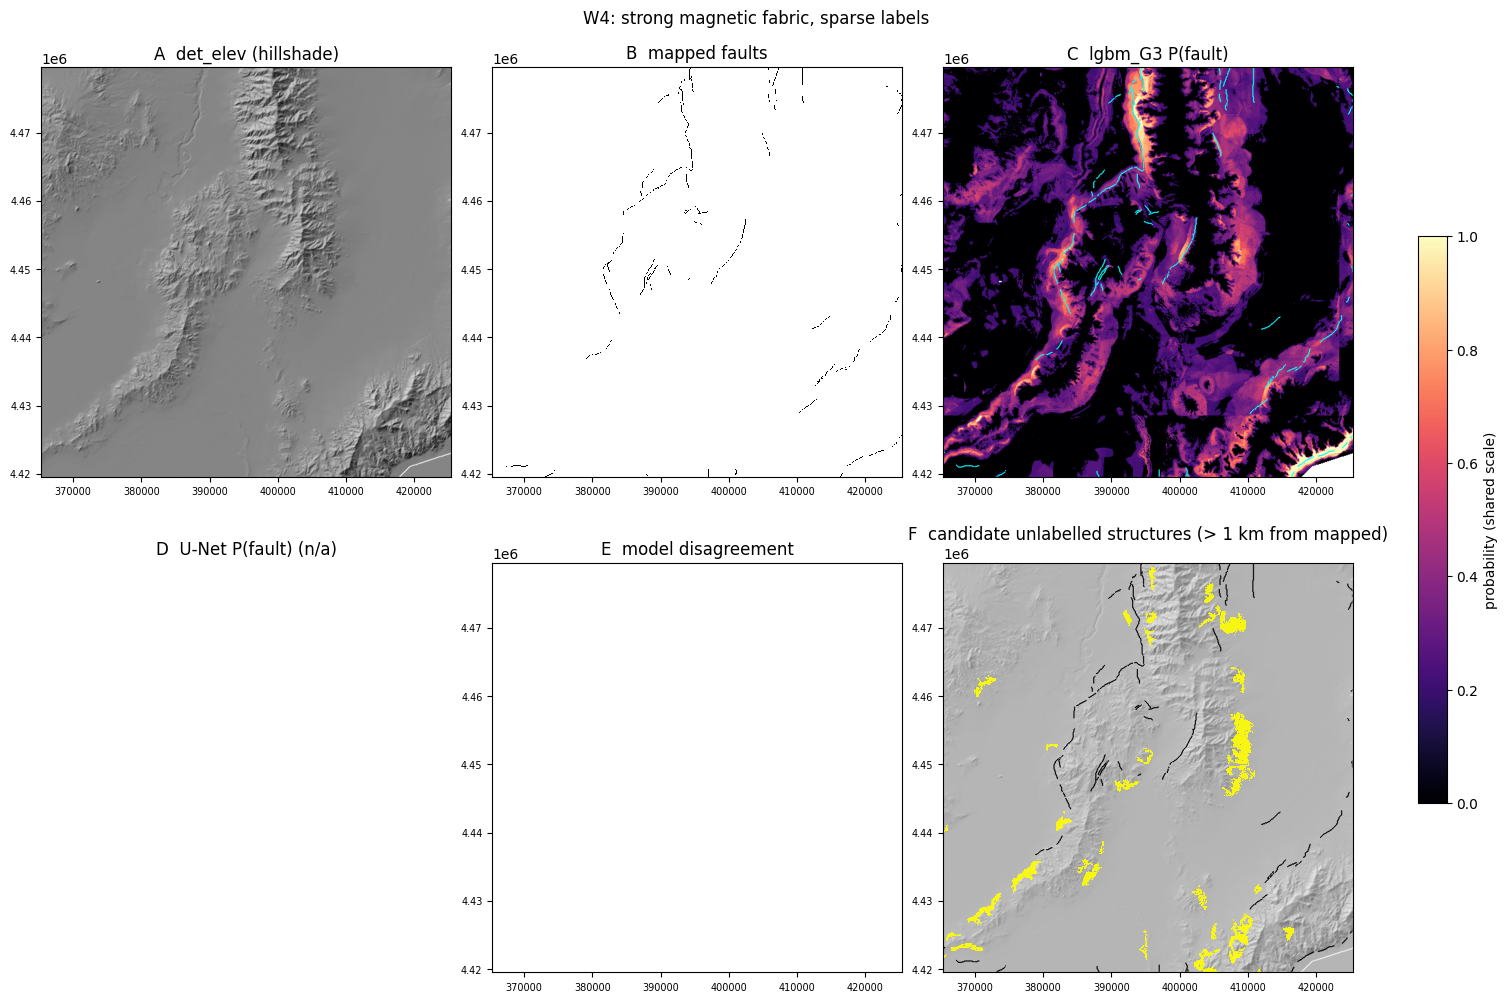

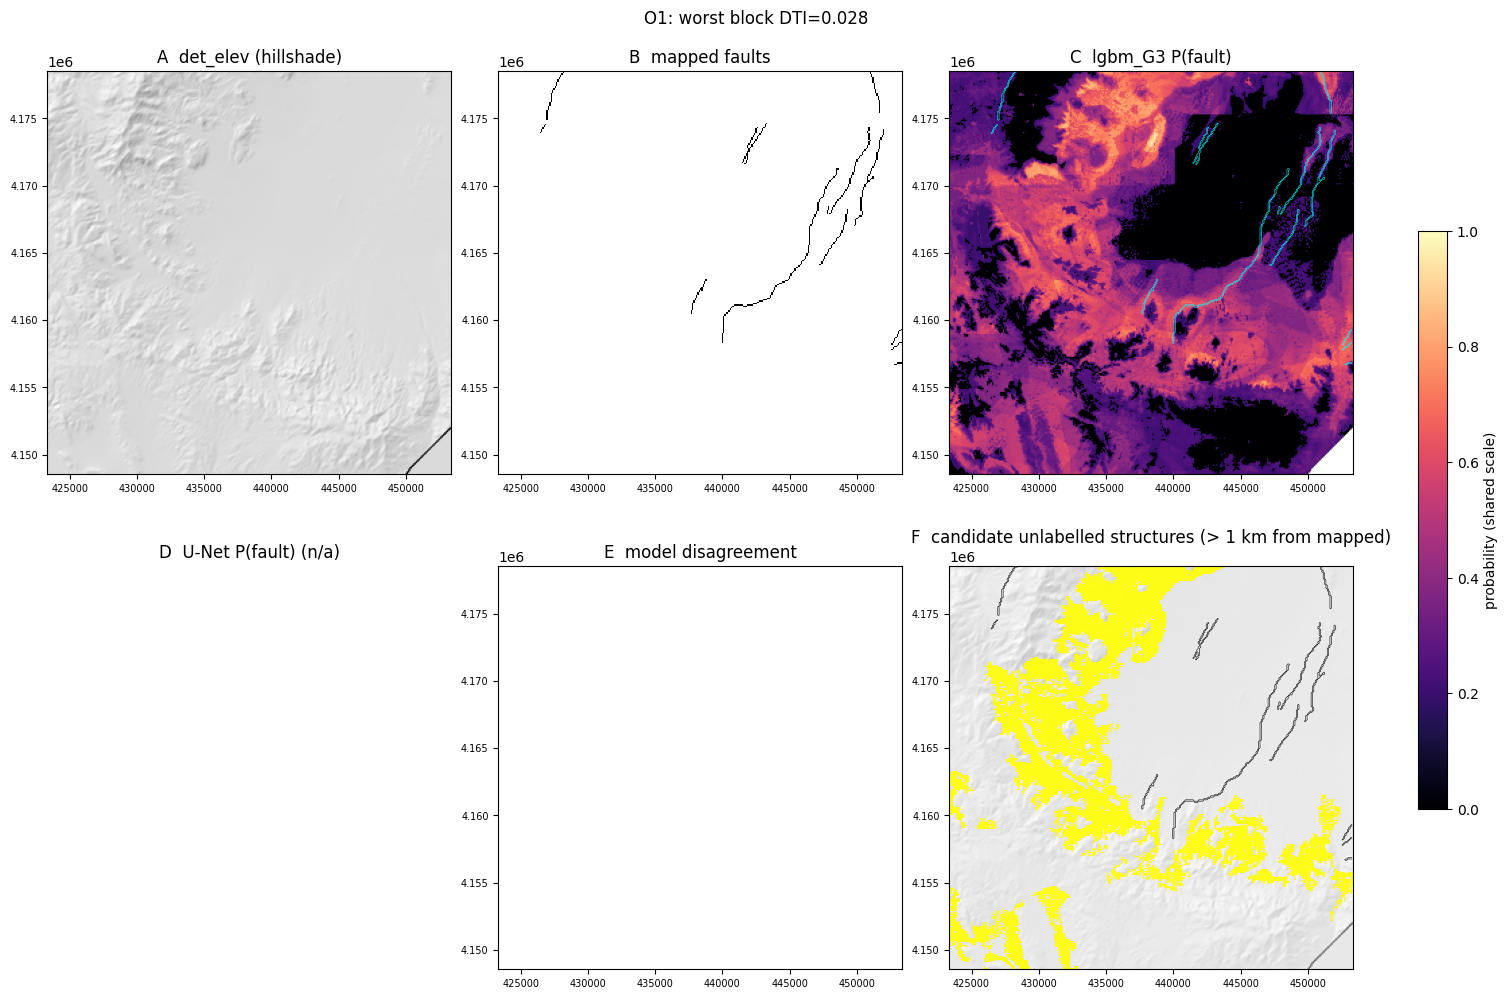

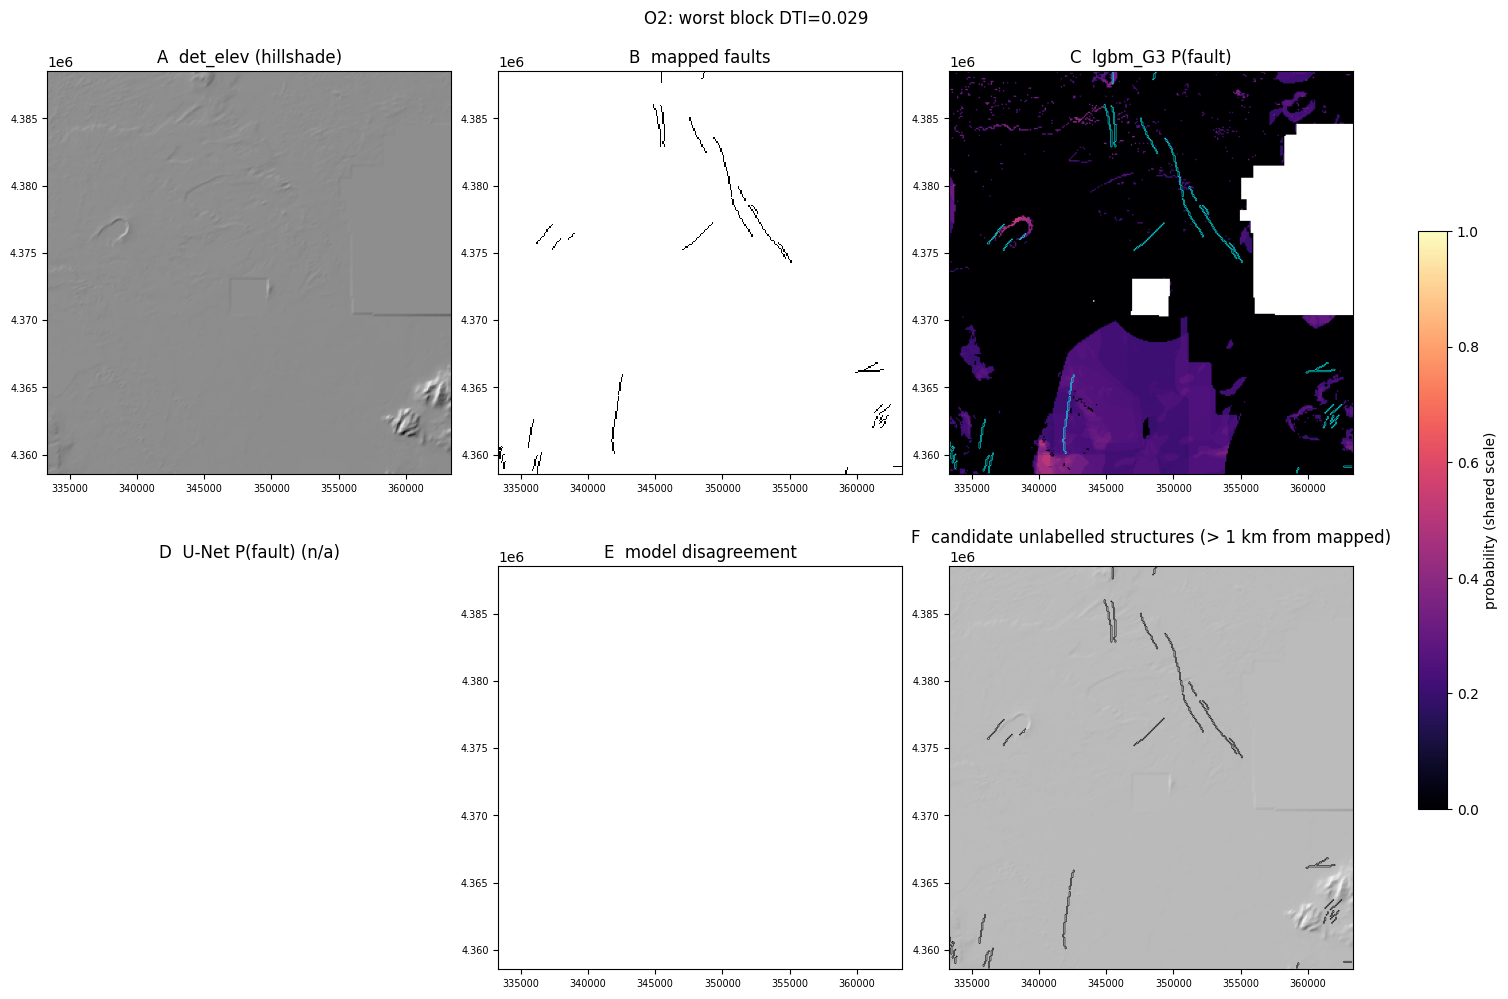

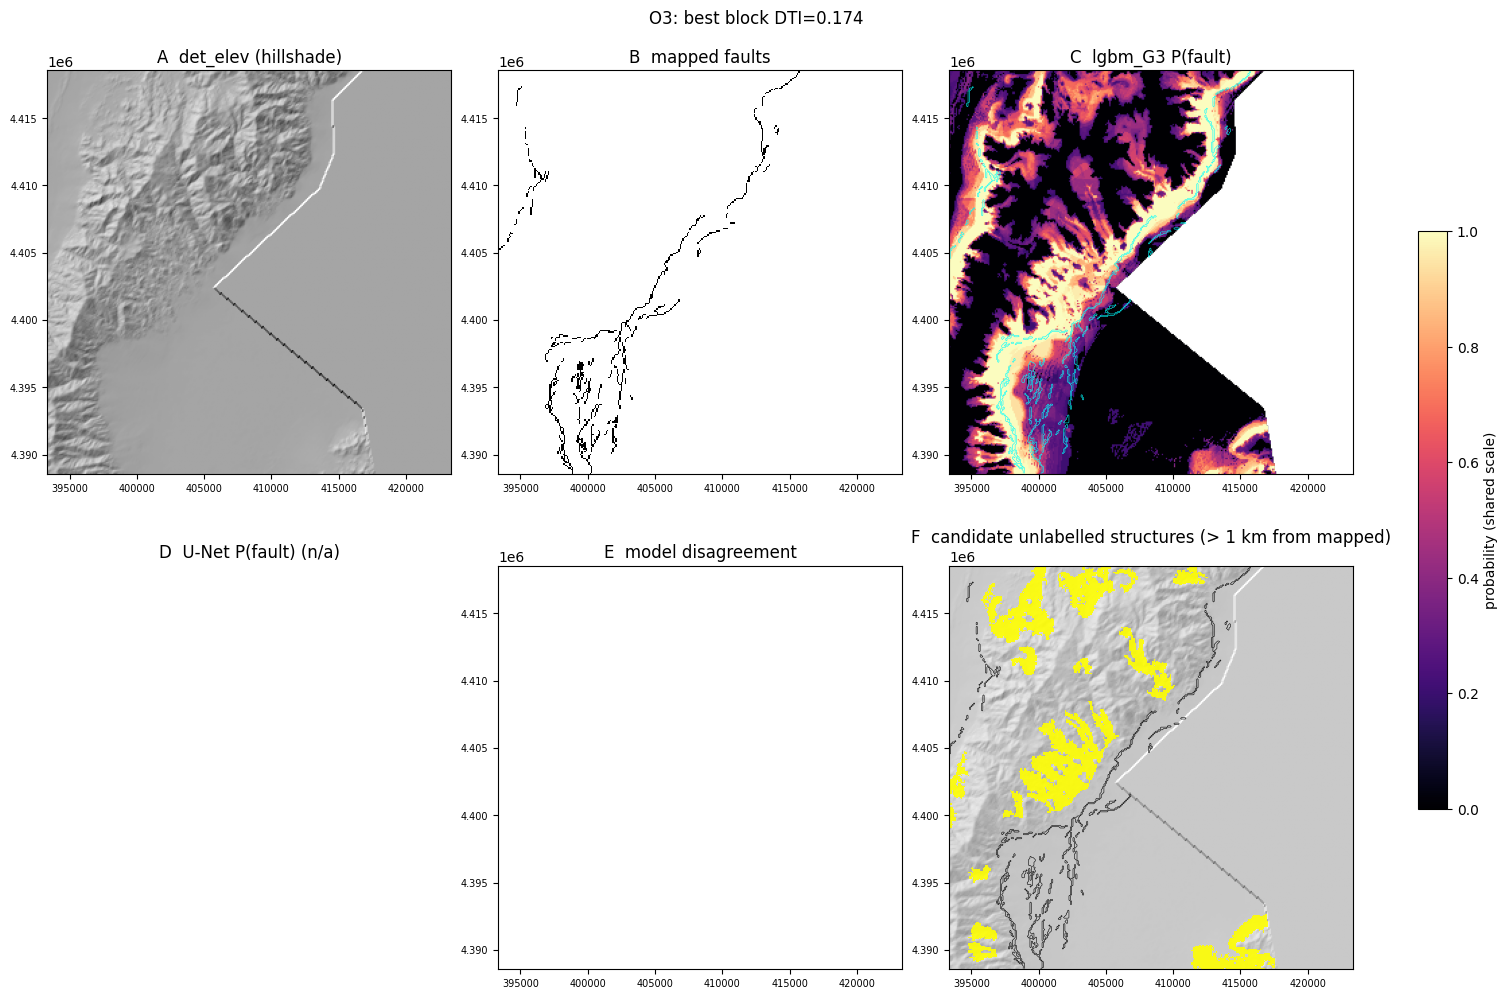

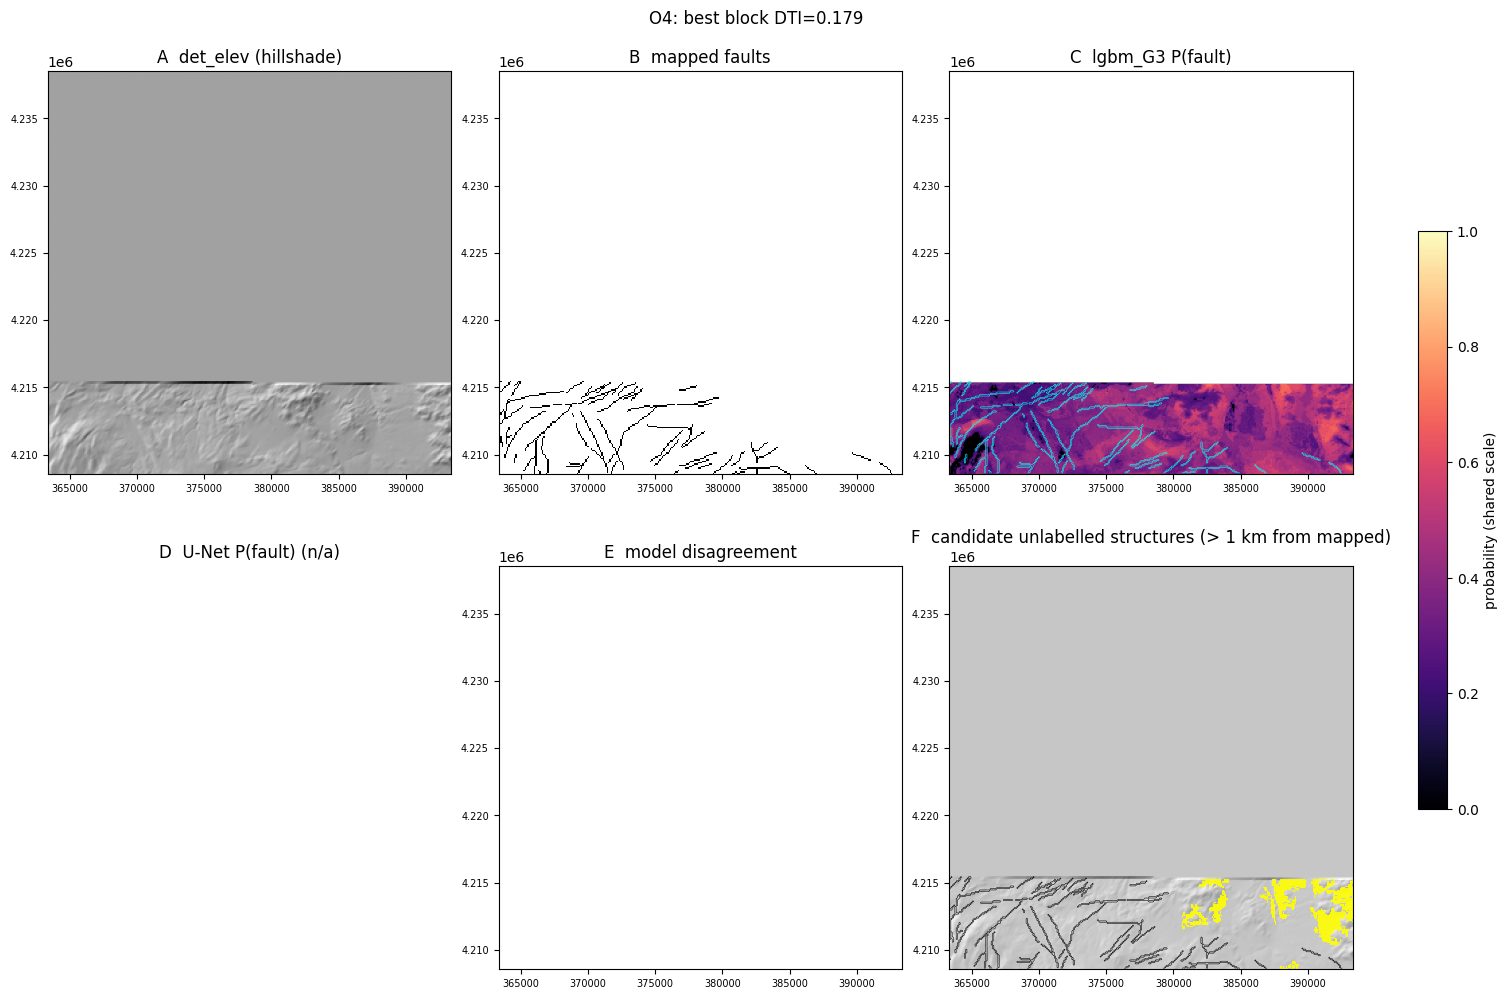

In [26]:
# Error atlas: Phase-1 windows W1-W4 + objective best/worst 30 km blocks of the primary GBM
PRIMARY_GBM = BEST_GBM or 'lgbm_G1'
blocks = geo_eval.block_dti(MAPS[PRIMARY_GBM], data)
save_table(blocks, 'block_dti_primary_gbm', '30 km block DTI of the primary GBM (for objective windows)')
WINS = pd.concat([geo_eval.native_windows(data, EDA_WINDOWS), geo_eval.objective_windows(blocks, data)], ignore_index=True)
save_table(WINS, 'atlas_windows', 'Error-atlas windows on the native grid')

CAND, CAND_R = geo_eval.candidate_structures(MAPS[PRIMARY_GBM], data, CFG.report_threshold,
                                             eda_candidates=pd.read_parquet(PATHS.eda / 'datasets' / 'lineament_candidates.parquet'))
if len(CAND):
    CAND.to_parquet(PATHS.out / 'datasets' / 'candidate_structures_primary_gbm.parquet', index=False)
    gp = geo_eval.write_candidates_gpkg(CAND_R, CAND, data, PATHS.out / 'datasets' / 'candidate_structures_primary_gbm.gpkg')
    MAN.add('candidate_structures', Path(gp), 'vector', 'High-probability structures > 1 km from mapped faults (exploratory)')
    display(CAND.head(10).round(3))

elev = np.asarray(store.get('raw:det_elev'))
cnn_map = MAPS.get(BEST_CNN) if BEST_CNN else None
for w in WINS.itertuples():
    fig = geo_eval.atlas_figure(w, data, elev, MAPS[PRIMARY_GBM], cnn_map, CAND_R,
                                names=(PRIMARY_GBM, BEST_CNN or 'U-Net'))
    save_fig(fig, f'atlas_{w.name}', f'Error atlas {w.name}: {w.label}')

In [27]:
# Do confident predictions far from mapped faults follow strong geophysical boundaries?
edge = np.asarray(store.get('magnetic:thdr@2km')) if store.has('magnetic:thdr@2km') else np.asarray(store.get('raw:tmi_hg'))
sb = pd.DataFrame([{'model': m, **geo_eval.strong_boundaries_without_labels(p, edge, data)} for m, p in MAPS.items()])
save_table(sb, 'confident_far_predictions_on_edges', 'Share of confident predictions > 2 km from labels lying on top-5% magnetic edges')
display(sb.round(3))

,model,far_px,confident_far_px,share_confident_on_strong_edge,base_rate_strong_edge,edge_quantile
0,lgbm_G1,2848270,2391768,0.049,0.046,0.95
1,lgbm_G3,2848270,275043,0.073,0.046,0.95
2,B0_lineament,2848270,490313,0.087,0.046,0.95


## 7 · Pseudo-discovery evaluation

One model per split trains on all labels except the withheld systems (+1 km ignore ring, weight 0). GBMs use the median best iteration of their geographic CV run; CNNs a fixed epoch budget. Predictions are scored only inside the 10 km evaluation zone around the withheld systems, with retained (training) faults excluded (`dti_excl_retained`) and, for sensitivity, not excluded (`dti_no_exclusion`). The CV run's output transform is applied so that scales match §4–5.

> Controlled stress test of missing-label generalisation, not an estimate of the hidden-test score. Background FP inside the evaluation zone is optimistic because those pixels were training negatives.

In [29]:

# ============================================================
# PSEUDO-DISCOVERY BENCHMARK — COMPLETE FIXED CELL
# ============================================================

import numpy as np
import pandas as pd

DISC_MODELS = [
    m for m in dict.fromkeys(
        ["lgbm_G1", "lgbm_G2", BEST_GBM]
    )
    if m in RUNS and RUNS[m].done
]

DISC_CNN = BEST_CNN if (RUN_CNN and BEST_CNN) else None


def fixed_sensitivity_tables(per_sys, seg_raster, seg_table, splits):
    """
    Fix missing n_px in discovery.sensitivity_tables().

    Uses the existing implementation if n_px is present.
    Otherwise reconstructs n_px from the withheld-system
    evaluation raster when system identifiers can be matched.

    If exact pixel counts cannot be reconstructed, uses
    trace_km as an explicitly identified approximation.
    """

    df = per_sys.copy()

    if "n_px" not in df.columns:

        # Check for equivalent pixel-count fields
        alternatives = [
            "n_pixels",
            "pixel_count",
            "n_fault_pixels",
            "fault_pixel_count",
        ]

        found = next(
            (c for c in alternatives if c in df.columns),
            None
        )

        if found is not None:
            df["n_px"] = df[found].astype(float)
            weight_basis = found

        else:
            # Fast recovery using fault-trace length.
            # This is an approximation, NOT the exact
            # positive-pixel weighting.
            if "trace_km" not in df.columns:
                raise ValueError(
                    "No pixel counts or trace_km available "
                    "for discovery sensitivity weighting."
                )

            df["n_px"] = df["trace_km"].astype(float)
            weight_basis = "trace_km_APPROXIMATION"

    else:
        weight_basis = "n_px"

    weights = pd.to_numeric(
        df["n_px"], errors="coerce"
    )

    if (
        weights.isna().any()
        or (~np.isfinite(weights)).any()
        or (weights < 0).any()
    ):
        raise ValueError(
            "Invalid sensitivity weights in DISC_SYS."
        )

    print(f"Sensitivity weighting: {weight_basis}")

    result = disc.sensitivity_tables(
        df,
        seg_raster,
        seg_table,
        splits
    )

    result["weight_basis"] = weight_basis

    return result


# ------------------------------------------------------------
# 1. Run discovery inference only when necessary
# ------------------------------------------------------------

if RUN_DISCOVERY:

    reuse_existing = (
        "DISC_SUM" in globals()
        and "DISC_SYS" in globals()
        and isinstance(DISC_SUM, pd.DataFrame)
        and isinstance(DISC_SYS, pd.DataFrame)
        and not DISC_SUM.empty
        and not DISC_SYS.empty
        and not OVERWRITE
    )

    if reuse_existing:
        print("Reusing existing discovery evaluation results.")

    else:
        disc_summary_rows = []
        disc_system_rows = []

        for d in range(splits.n_splits):

            print(
                f"\n{'=' * 60}\n"
                f"PSEUDO-DISCOVERY SPLIT {d + 1}/"
                f"{splits.n_splits}\n"
                f"{'=' * 60}"
            )

            ign = splits.ignore(d)
            zone = splits.eval_zone(d) & data.valid

            preds = {}

            # ------------------------------------------------
            # LightGBM models
            # ------------------------------------------------

            for m in DISC_MODELS:

                cv = RUNS[m]

                r = fit_full_gbm(
                    f"disc{d}_{cv.exp_id}",
                    cv.config["features"],
                    data,
                    store,
                    CFG,
                    data.valid,
                    median_best_iteration(cv),
                    ignore_mask=ign,
                    predict_area=zone,
                    extra_config={
                        "discovery_split": d,
                        "cv_run": cv.exp_id,
                    },
                    overwrite=OVERWRITE,
                )

                preds[m] = apply_transform_file(
                    read_map(r.dir / "pred.tif"),
                    load_transform(cv.dir)
                )

            # ------------------------------------------------
            # CNN model
            # ------------------------------------------------

            if DISC_CNN:

                from gems_bench.cnn import run_cnn_full

                spec = CNN_SPECS[DISC_CNN][0]

                r = run_cnn_full(
                    f"disc{d}_{RUNS[DISC_CNN].exp_id}",
                    spec,
                    data,
                    store,
                    ignore_mask=ign,
                    predict_area=zone,
                    extra_config={
                        "discovery_split": d
                    },
                    overwrite=OVERWRITE,
                )

                preds[DISC_CNN] = apply_transform_file(
                    read_map(r.dir / "pred.tif"),
                    load_transform(RUNS[DISC_CNN].dir)
                )

            # ------------------------------------------------
            # Unsupervised lineament baseline
            # ------------------------------------------------

            if "B0_lineament" in RUNS:
                preds["B0_lineament"] = oof_tf(
                    RUNS["B0_lineament"]
                )

            # ------------------------------------------------
            # Evaluate predictions
            # ------------------------------------------------

            for m, p in preds.items():

                s, per = disc.evaluate_split(
                    p,
                    data,
                    splits,
                    d,
                    m,
                    threshold=CFG.report_threshold
                )

                disc_summary_rows.append(s)
                disc_system_rows.append(per)

                print(
                    f"split {d} | {m:<18s} | "
                    f"DTI(excl)={s['dti_excl_retained']:.4f} | "
                    f"w-recall={s['weighted_recall']:.3f} | "
                    f"recall@300={s['recall@300m']:.3f}"
                )

        if not disc_summary_rows or not disc_system_rows:
            raise RuntimeError(
                "Discovery evaluation produced no results."
            )

        DISC_SUM = pd.DataFrame(disc_summary_rows)

        DISC_SYS = pd.concat(
            disc_system_rows,
            ignore_index=True
        )

    # --------------------------------------------------------
    # 2. Save summary and system-level results
    # --------------------------------------------------------

    save_table(
        DISC_SUM,
        "pseudo_discovery_results",
        "Pseudo-discovery DTI / recall per model x split",
        PATHS.out
    )

    save_table(
        DISC_SYS,
        "pseudo_discovery_by_system",
        "Recall and confidence per withheld system",
        PATHS.out
    )

    # --------------------------------------------------------
    # 3. FIX: sensitivity table
    # --------------------------------------------------------

    SENS = fixed_sensitivity_tables(
        DISC_SYS,
        SEG,
        SEG_TAB,
        splits
    )

    save_table(
        SENS,
        "pseudo_discovery_sensitivity",
        "Withheld-system recall by length / region / strike",
        PATHS.out
    )

    # --------------------------------------------------------
    # 4. Overall model results
    # --------------------------------------------------------

    print("\n" + "=" * 70)
    print("PSEUDO-DISCOVERY MODEL COMPARISON")
    print("=" * 70)

    metrics = [
        "dti_excl_retained",
        "dti_no_exclusion",
        "weighted_recall",
        "recall@100m",
        "recall@200m",
        "recall@300m",
        "extra_confident_km2",
    ]

    metrics = [
        c for c in metrics
        if c in DISC_SUM.columns
    ]

    display(
        DISC_SUM.groupby("model")[metrics]
        .agg(["mean", "std"])
        .round(4)
    )

    # --------------------------------------------------------
    # 5. Sensitivity by geological subgroup
    # --------------------------------------------------------

    print("\n" + "=" * 70)
    print("SENSITIVITY BY GEOLOGICAL SUBGROUP")
    print("=" * 70)

    if not SENS.empty:

        display(
            SENS.pivot_table(
                index=["stratum", "value"],
                columns="model",
                values="weighted_recall"
            ).round(3)
        )

        if "recall@300m" in SENS.columns:

            display(
                SENS.pivot_table(
                    index=["stratum", "value"],
                    columns="model",
                    values="recall@300m"
                ).round(3)
            )

    else:
        print("No sensitivity strata available.")

    print("\nPseudo-discovery evaluation complete.")

else:
    print("RUN_DISCOVERY=False — discovery stage skipped.")


Reusing existing discovery evaluation results.
Sensitivity weighting: trace_km_APPROXIMATION

PSEUDO-DISCOVERY MODEL COMPARISON


dti_excl_retained         dti_no_exclusion         weighted_recall         recall@100m         recall@200m         recall@300m         extra_confident_km2          
                          mean     std             mean     std            mean     std        mean     std        mean     std        mean     std                mean       std
model                                                                                                                                                                            
B0_lineament            0.0326  0.0074           0.0728  0.0027          0.2948  0.0903      0.2915  0.0906      0.3073  0.0911      0.3285  0.0929           2148.8000  194.5298
lgbm_G1                 0.0264  0.0011           0.0786  0.0062          0.7657  0.0318      0.9468  0.0239      0.9528  0.0248      0.9593  0.0244          10640.9467  756.2871
lgbm_G2                 0.0259  0.0012           0.0822  0.0039          0.7203  0.0296      0.9332  0.0313      0.9470  0.0256      0.9576  0.0215           9826.7667  215.2124
lgbm_G3                 0.0360  0.0026           0.1180  0.0020          0.4081  0.0093      0.4280  0.0348      0.4682  0.0431      0.5059  0.0527           1625.7000   87.3882


SENSITIVITY BY GEOLOGICAL SUBGROUP


model                         B0_lineament  lgbm_G1  lgbm_G2  lgbm_G3
stratum       value                                                  
length_bin    10-20                  0.203    0.741    0.693    0.359
              20-50                  0.336    0.756    0.727    0.399
              5-10                   0.228    0.704    0.734    0.367
              >50                    0.340    0.824    0.723    0.471
region_name   CC                     0.214    0.762    0.773    0.447
              CW                     0.225    0.706    0.662    0.309
              NC                     0.432    0.796    0.639    0.392
              NE                     0.426    0.693    0.654    0.364
              NW                     0.255    0.781    0.790    0.437
              SC                     0.229    0.816    0.763    0.450
              SE                     0.000    0.813    0.713    0.225
strike_sector (-0.001, 30.0]         0.296    0.790    0.738    0.425
              (120.0, 150.0]         0.250    0.820    0.829    0.539
              (150.0, 180.0]         0.292    0.754    0.668    0.348
              (30.0, 60.0]           0.385    0.700    0.684    0.399
              (60.0, 90.0]           0.145    0.699    0.745    0.379
              (90.0, 120.0]          0.179    0.763    0.720    0.379

model                         B0_lineament  lgbm_G1  lgbm_G2  lgbm_G3
stratum       value                                                  
length_bin    10-20                  0.247    0.970    0.939    0.432
              20-50                  0.367    0.937    0.963    0.479
              5-10                   0.252    0.928    0.984    0.465
              >50                    0.375    0.993    0.951    0.606
region_name   CC                     0.251    0.992    0.985    0.553
              CW                     0.258    0.948    0.898    0.254
              NC                     0.457    0.960    0.918    0.485
              NE                     0.446    0.837    0.935    0.435
              NW                     0.299    0.987    0.998    0.610
              SC                     0.270    0.990    0.986    0.595
              SE                     0.000    1.000    1.000    0.000
strike_sector (-0.001, 30.0]         0.324    0.975    0.980    0.515
              (120.0, 150.0]         0.287    0.989    1.000    0.832
              (150.0, 180.0]         0.332    0.978    0.905    0.436
              (30.0, 60.0]           0.425    0.867    0.929    0.499
              (60.0, 90.0]           0.183    0.950    0.996    0.370
              (90.0, 120.0]          0.218    0.953    1.000    0.365


Pseudo-discovery evaluation complete.


## 8 · Model complementarity and OOF ensembles

All inputs are stitched OOF maps on the same folds, so ensembles of them are valid OOF predictions. Weights (simplex, step 0.1) and the output transform are cross-fitted across folds. No leaderboard feedback is used.

In [30]:
ENS = None
if RUN_ENSEMBLE:
    learned = report.benchmark_summary(PATHS, RUNS)
    learned = learned[(learned.status == 'done') & learned.family.isin(['gbm', 'cnn'])]
    TOP = list(learned.sort_values('dti_pooled_crossfit_tf', ascending=False).model.head(3))
    if BEST_CNN and BEST_CNN not in TOP and len(TOP) == 3:
        TOP[-1] = BEST_CNN                       # always test cross-family complementarity
    print('ensemble members:', TOP)
    agree = pairwise_agreement({m: oof_tf(RUNS[m]) for m in TOP}, data.valid, data.labels, RNG)
    rec_m = {m: REC[m] if m in REC else geo_eval.segment_recovery(oof_tf(RUNS[m]), data, SEG, SEG_TAB, folds.fold_map) for m in TOP}
    _, over = geo_eval.recovery_overlap(rec_m)
    dis = agree.merge(over[['model_a', 'model_b', 'both_km', 'only_a_km', 'only_b_km', 'jaccard_segments']],
                      on=['model_a', 'model_b'], how='left')
    save_table(dis, 'model_disagreement', 'Pairwise OOF correlation, top-q% Jaccard, segment-recovery overlap', PATHS.out)
    display(dis.round(3))
    if len(TOP) >= 2:
        ENS = build_ensembles({m: RUNS[m] for m in TOP}, data, folds.fold_map, PATHS.ensembles)
        MAN.add('ensemble_summary', PATHS.ensembles / 'ensemble_summary.csv', 'table', 'OOF ensembles (cross-fitted)')
        display(ENS.round(4))

ensemble members: ['lgbm_G3', 'lgbm_G4', 'lgbm_G2']


,model_a,model_b,pearson,spearman,jaccard_top0.01,label_hit_only_a_top0.01,label_hit_only_b_top0.01,jaccard_top0.03,label_hit_only_a_top0.03,label_hit_only_b_top0.03,jaccard_top0.1,label_hit_only_a_top0.1,label_hit_only_b_top0.1,both_km,only_a_km,only_b_km,jaccard_segments
0,lgbm_G3,lgbm_G4,0.689,0.738,0.159,0.001,0.115,0.356,0.017,0.083,0.476,0.068,0.057,1623.325,2.531,2559.879,0.335
1,lgbm_G3,lgbm_G2,0.503,0.620,0.049,0.025,0.076,0.117,0.059,0.061,0.321,0.118,0.068,1616.594,9.263,3455.537,0.271
2,lgbm_G4,lgbm_G2,0.344,0.490,0.131,0.119,0.056,0.131,0.119,0.056,0.271,0.117,0.078,3894.410,288.793,1177.721,0.694


C:\Users\myben\Downloads\GEMS\gems_bench\ensemble.py:109: RuntimeWarning: Mean of empty slice
  "mean": np.nanmean(np.stack([maps[k] for k in names]), 0),
C:\Users\myben\Downloads\GEMS\gems_bench\ensemble.py:110: RuntimeWarning: Mean of empty slice
  "rank_mean": np.nanmean(np.stack([rank_normalise(maps[k], data.valid) for k in names]), 0),


,ensemble,dti_crossfit_tf,fold_min,fold_max,path
0,mean,0.0757,0.0668,0.0882,C:\Users\myben\Downloads\GEMS\outputs\benchmar...
1,rank_mean,0.1125,0.0537,0.1281,C:\Users\myben\Downloads\GEMS\outputs\benchmar...
2,weighted,0.0815,0.0681,0.0951,C:\Users\myben\Downloads\GEMS\outputs\benchmar...
3,"weighted(weights only, no transform)",0.0612,NaN,NaN,NaN


## 9 · First leaderboard submission candidates (written, never uploaded)

Fold-average inference over the full region, then the output transform fitted on all OOF folds. Two variants per candidate: `model` and `model_max_known` (mapped faults set to 1) — only leaderboard feedback can tell whether known faults count in scoring. Every file is checked against `example_submission.tif` (CRS, transform, shape, float32, [0, 1], NaN outside the footprint).

In [31]:
SUBS = []
FULL_DIR = PATHS.submissions / 'full_maps'
FULL_DIR.mkdir(exist_ok=True)

def full_map(m):
    p = FULL_DIR / f'{RUNS[m].exp_id}.tif'
    if p.exists() and not OVERWRITE:
        return read_map(p)
    r = RUNS[m]
    arr = submission.gbm_full_map(r, data, store) if r.family == 'gbm' else submission.cnn_full_map(r, data, store)
    submission.save_full_map(arr, data, p)
    return arr

if RUN_SUBMISSION:
    for m in [x for x in (BEST_GBM, BEST_CNN) if x]:
        SUBS += submission.export_candidate(f'{m}', full_map(m), data, load_transform(RUNS[m].dir),
                                            PATHS.submissions, meta={'exp_id': RUNS[m].exp_id})
    if ENS is not None and len(ENS):
        best_ens = ENS.dropna(subset=['path']).sort_values('dti_crossfit_tf').iloc[-1]
        cfg_e = json.loads(Path(best_ens.path).with_suffix('.json').read_text())
        members = {m: full_map(m) for m in cfg_e['members']}
        e = submission.ensemble_full_map(members, cfg_e, data)
        SUBS += submission.export_candidate(f'ens_{best_ens.ensemble}', e, data, cfg_e['output_transform'],
                                            PATHS.submissions, meta={'members': cfg_e['members']})
    SUB_TAB = pd.DataFrame(SUBS)
    if len(SUB_TAB):
        save_table(SUB_TAB.drop(columns=['transform'], errors='ignore'), 'submission_candidates', 'Exported submission files + sanity checks', PATHS.submissions)
        display(SUB_TAB[['candidate', 'policy', 'path', 'min', 'max', 'mean_inside', 'frac_ge_0_5', 'finite_inside_valid']])

  predicted full grid with fold0.txt
  predicted full grid with fold1.txt
  predicted full grid with fold2.txt


C:\Users\myben\Downloads\GEMS\gems_bench\submission.py:42: RuntimeWarning: Mean of empty slice
  return np.nanmean(np.stack(maps), 0)


  predicted full grid with fold0.txt
  predicted full grid with fold1.txt
  predicted full grid with fold2.txt


C:\Users\myben\Downloads\GEMS\gems_bench\submission.py:42: RuntimeWarning: Mean of empty slice
  return np.nanmean(np.stack(maps), 0)


  predicted full grid with fold0.txt
  predicted full grid with fold1.txt
  predicted full grid with fold2.txt


C:\Users\myben\Downloads\GEMS\gems_bench\submission.py:124: RuntimeWarning: Mean of empty slice
  return np.nanmean(np.stack([rank_normalise(member_maps[k], data.valid) for k in names]), 0)


,candidate,policy,path,min,max,mean_inside,frac_ge_0_5,finite_inside_valid
0,lgbm_G3,model,C:\Users\myben\Downloads\GEMS\outputs\benchmar...,0.0,1.0,0.223629,0.136270,1.0
1,lgbm_G3,model_max_known,C:\Users\myben\Downloads\GEMS\outputs\benchmar...,0.0,1.0,0.229422,0.141997,1.0
2,ens_rank_mean,model,C:\Users\myben\Downloads\GEMS\outputs\benchmar...,0.0,1.0,0.184060,0.184060,1.0
3,ens_rank_mean,model_max_known,C:\Users\myben\Downloads\GEMS\outputs\benchmar...,0.0,1.0,0.188455,0.188455,1.0


## 10 · Experiment report and next decision

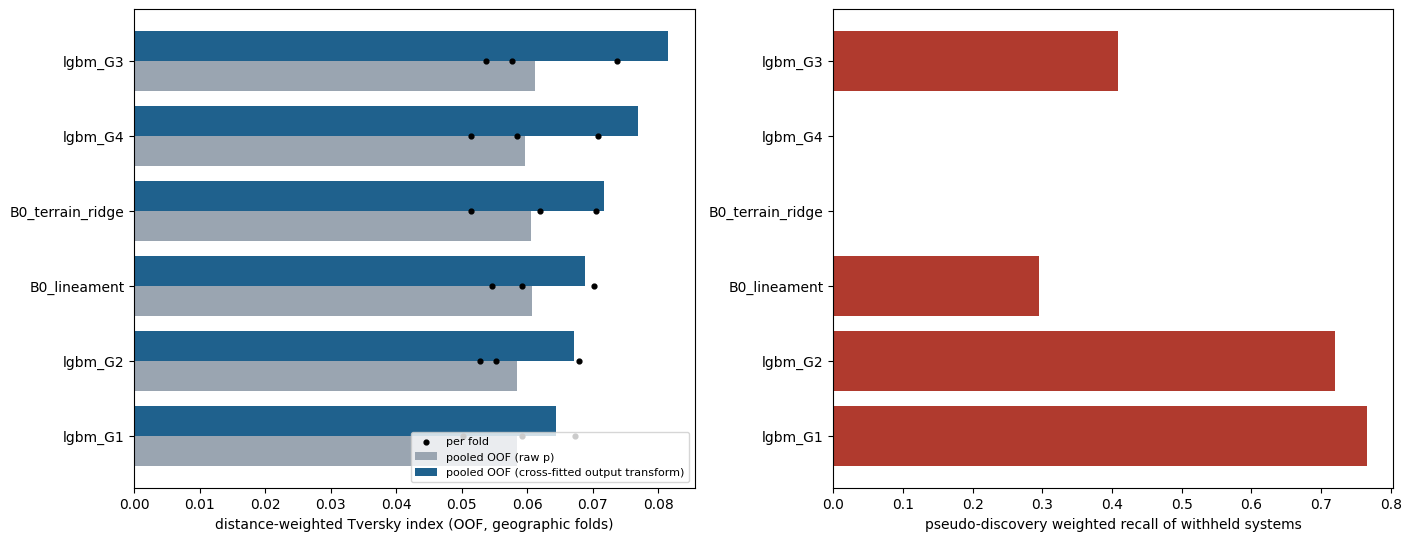

# GEMS — Phase 2 benchmark findings

_Generated 2026-10-20 20:54 by `notebooks/02_fault_benchmark.ipynb` from saved artifacts. All scores are out-of-fold on geographic folds (not leaderboard scores)._

## Results

| model            |   dti_pooled_raw |   dti_pooled_crossfit_tf |   dti_fold_mean |   dti_fold_std |   dti_fold_min |   recall@100m |   precision@100m |   pseudo_discovery_recall_w |
|:-----------------|-----------------:|-------------------------:|----------------:|---------------:|---------------:|--------------:|-----------------:|----------------------------:|
| B0_lineament     |           0.0607 |                   0.0688 |          0.0614 |         0.0065 |         0.0547 |        0.5918 |           0.0404 |                      0.2948 |
| B0_terrain_ridge |           0.0606 |                   0.0717 |          0.0613 |         0.0078 |         0.0513 |        0.6665 |           0.0405 |                    nan      |
| lgbm_G1          |           0.0584 |                   0.0644 |          0.0589 |         0.007  |         0.0502 |        0.6615 |           0.0548 |                      0.7657 |
| lgbm_G2          |           0.0585 |                   0.0671 |          0.0586 |         0.0067 |         0.0528 |        0.5202 |           0.0517 |                      0.7203 |
| lgbm_G3          |           0.0612 |                   0.0815 |          0.0617 |         0.0087 |         0.0536 |        0.5216 |           0.0613 |                      0.4081 |
| lgbm_G4          |           0.0597 |                   0.0769 |          0.0602 |         0.008  |         0.0514 |        0.5007 |           0.0607 |                    nan      |

## Decisions

**1. Primary baseline:** `lgbm_G3` (pooled cross-fitted DTI 0.0815, worst fold 0.0536). Candidates within one fold-std of the leader: lgbm_G3, lgbm_G4; the most fold-robust of them was chosen.

**2. Do non-terrain modalities add value (G2 raw-all vs G1 terrain-only)?** verdict = **inconclusive** (mean ΔDTI -0.0002, per fold {0: 0.0026, 1: 0.0007, 2: -0.0041}).
   - gain → keep all modalities; inconclusive → keep them but test modality-drop ablations on G3; loss → terrain-only is the stronger prior, drop low-SHAP modalities before Phase 3.

**3. Is multi-scale feature engineering worth keeping (G3 vs G2)?** verdict = **inconclusive** (mean ΔDTI 0.0030). Regional context (G4 vs G3): **inconclusive** (mean ΔDTI -0.0015).
   - keep engineered layers only on a 'gain' verdict; on 'inconclusive' keep the top-SHAP subset only.

**4. U-Net vs LightGBM:** not evaluated (one family missing).

**5. Poorly recovered fault types (primary model, strata with ≥ 20 segments):**

| stratum       | value          |   n_segments |   trace_km |   weighted_recall |
|:--------------|:---------------|-------------:|-----------:|------------------:|
| region_name   | NE             |          302 |    695.489 |             0.307 |
| fold          | 2              |          767 |   1969.53  |             0.318 |
| region_name   | CW             |          236 |    483.113 |             0.329 |
| length_bin    | <1             |          681 |    493.074 |             0.334 |
| strike_sector | (120.0, 150.0] |          209 |    576.618 |             0.338 |

**6. Next research phase:** **ensembling** — the best OOF ensemble adds 0.031 DTI over the primary baseline.
   Rule order: PU first if pseudo-discovery recall < 0.7 × geographic recall; else architecture if CNN − GBM > 0.02; else ensembling if ensemble gain > 0.01; else targets / post-processing.

## Pseudo-discovery (withheld fault systems)

| model        |   dti_excl_retained |   dti_no_exclusion |   weighted_recall |   recall@100m |   recall@300m |   extra_confident_km2 |
|:-------------|--------------------:|-------------------:|------------------:|--------------:|--------------:|----------------------:|
| B0_lineament |              0.0326 |             0.0728 |            0.2948 |        0.2915 |        0.3285 |               2148.8  |
| lgbm_G1      |              0.0264 |             0.0786 |            0.7657 |        0.9468 |        0.9593 |              10640.9  |
| lgbm_G2      |              0.0259 |             0.0822 |            0.7203 |        0.9332 |        0.9576 |               9826.77 |
| lgbm_G3      |              0.036  |             0.118  |            0.4081 |        0.428  |        0.5059 |               1625.7  |

## Ensembles (OOF, cross-fitted)

| ensemble                             |   dti_crossfit_tf |   fold_min |   fold_max | path                                                                        |
|:-------------------------------------|------------------:|-----------:|-----------:|:----------------------------------------------------------------------------|
| mean                                 |            0.0757 |     0.0668 |     0.0882 | C:\Users\myben\Downloads\GEMS\outputs\benchmark\ensembles\ens_mean.tif      |
| rank_mean                            |            0.1125 |     0.0537 |     0.1281 | C:\Users\myben\Downloads\GEMS\outputs\benchmark\ensembles\ens_rank_mean.tif |
| weighted                             |            0.0815 |     0.0681 |     0.0951 | C:\Users\myben\Downloads\GEMS\outputs\benchmark\ensembles\ens_weighted.tif  |
| weighted(weights only, no transform) |            0.0612 |   nan      |   nan      | nan                                                                         |

## Caveats

- Geographic OOF DTI scores mapped USGS faults in held-out regions; the hidden test scores expert-mapped *new* faults.
- Phase-1 transform/scale choices used all labels (mild selection effect on G3/G4).
- Filters wider than the fold buffer see validation-area inputs (never labels): see `tables/leakage_audit.csv`.
- Known-fault policy for submissions (`model` vs `model_max_known`) is unresolved until leaderboard feedback.

In [34]:
disc_df = DISC_SUM if isinstance(DISC_SUM, pd.DataFrame) and len(DISC_SUM) else None
SUMMARY = report.benchmark_summary(PATHS, RUNS, discovery=disc_df)
save_table(SUMMARY, 'benchmark_summary', 'One row per model: OOF DTI, fold spread, diagnostics, runtime, pseudo-discovery', PATHS.out)
fts = {k: report.fold_table(r) for k, r in RUNS.items() if r.done}
fig = report.comparison_figure(SUMMARY, fts)
fig.savefig(PATHS.out / 'model_comparison.png', dpi=140, bbox_inches='tight')
MAN.add('model_comparison', PATHS.out / 'model_comparison.png', 'figure', 'Pooled/fold OOF DTI and pseudo-discovery recall')
plt.show()

roles = {'G1': 'lgbm_G1', 'G2': 'lgbm_G2', 'G3': 'lgbm_G3', 'G4': 'lgbm_G4', 'CNN_A': 'cnn_A_bcedice', 'CNN_B': 'cnn_B_bcedice'}
prim_arch = STRAT[STRAT.model == (BEST_GBM or ANALYSE[0])] if 'STRAT' in dir() and len(STRAT) else None
fp = report.write_findings(PATHS.out / 'BENCHMARK_FINDINGS.md', SUMMARY, RUNS, archetype=prim_arch,
                           discovery=disc_df, ensembles=ENS, roles=roles)
MAN.add('benchmark_findings', fp, 'report', 'Phase-2 findings with rule-based decisions')
display(Markdown(fp.read_text(encoding='utf-8')))